# Mineral Image Classifier

## 01. Prepare dataset

In [3]:
import torch
import torchvision

from pathlib import Path
from torch import nn
from torchvision import transforms
from torchmetrics import Accuracy

from helper_function.helper_functions import set_seeds, plot_loss_curves

In [16]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

We will be using the [Mineral Photos Database](https://www.kaggle.com/datasets/floriangeillon/mineral-photos) from Kaggle.  
Since we are building a model from scratch, it’s better to start small. Therefore, we will initially work with **20% of the original dataset** to tune our model. Additionally, we will focus on **only 5 mineral classes**, as the goal of this project is to demonstrate the end-to-end process of building a custom model rather than completing a full large-scale classification task.

Let's take a look to our dataset.

In [3]:
from pathlib import Path

# Create data paths
data_path = Path("data/")
train_dir = data_path / "train"
test_dir = data_path / "test"

# Count the amount of files per type of mineral.

counter = 0
for subfolder in train_dir.iterdir():
    if subfolder.is_dir():
        counter += 1
        count = sum(1 for _ in subfolder.iterdir() if _.is_file())
        print(counter, subfolder.name, count)    

1 azurite 1250
2 baryte 2211
3 beryl 1615
4 calcite 6574
5 cerussite 1367
6 copper 1429
7 fluorite 5669
8 gypsum 1351
9 hematite 1284
10 malachite 1607
11 pyrite 2339
12 pyromorphite 1705
13 quartz 8244
14 smithsonite 1188
15 wulfenite 1521


So, as we stated before, we are going to choose mineral class to work with onthis project. We will select the 5 most likely to be found when exploring ore deposits in Chile. These are going to be:
1. Copper (Cu)
2. Azurite (Cu₃(CO₃)₂(OH)₂)
3. Malachite (Cu₂CO₃(OH)₂)
4. Pyrite (FeS₂)
5. Quartz (SiO₂)

Now that we have selected our mineral classes to work with, let's retrieve the 20% of the original data of each mineral class selected.

In [1]:
from helper_function.new_dataset import new_dataset

# We are goign to retrieve just 20% of the original data from the selected mineral classes
# This custom function assumes we have our data folder in our current directory to work.
new_dataset(perc_amount=20,
            subfolders=["copper", "azurite", "malachite", "pyrite", "quartz"])

Copying 20% of copper data into data_20_percent\train
Copying 20% of azurite data into data_20_percent\train
Copying 20% of malachite data into data_20_percent\train
Copying 20% of pyrite data into data_20_percent\train
Copying 20% of quartz data into data_20_percent\train
Copying 20% of copper data into data_20_percent\test
Copying 20% of azurite data into data_20_percent\test
Copying 20% of malachite data into data_20_percent\test
Copying 20% of pyrite data into data_20_percent\test
Copying 20% of quartz data into data_20_percent\test
✔ Done! Folder 'data_20_percent' created with 20% of the original dataset.


Let's take a look to our new dataset

In [4]:
# Create data paths
data_path = Path("data/")
data_20_percent = data_path / "data_20_percent"
train_dir = data_20_percent / "train"
test_dir = data_20_percent / "test"

# Count the amount of files per type of mineral.

counter = 0
for subfolder in train_dir.iterdir():
    if subfolder.is_dir():
        counter += 1
        count = sum(1 for _ in subfolder.iterdir() if _.is_file())
        print(counter, subfolder.name, count)   

1 azurite 250
2 copper 286
3 malachite 321
4 pyrite 468
5 quartz 1649


### 1.2 Visualizing dataset

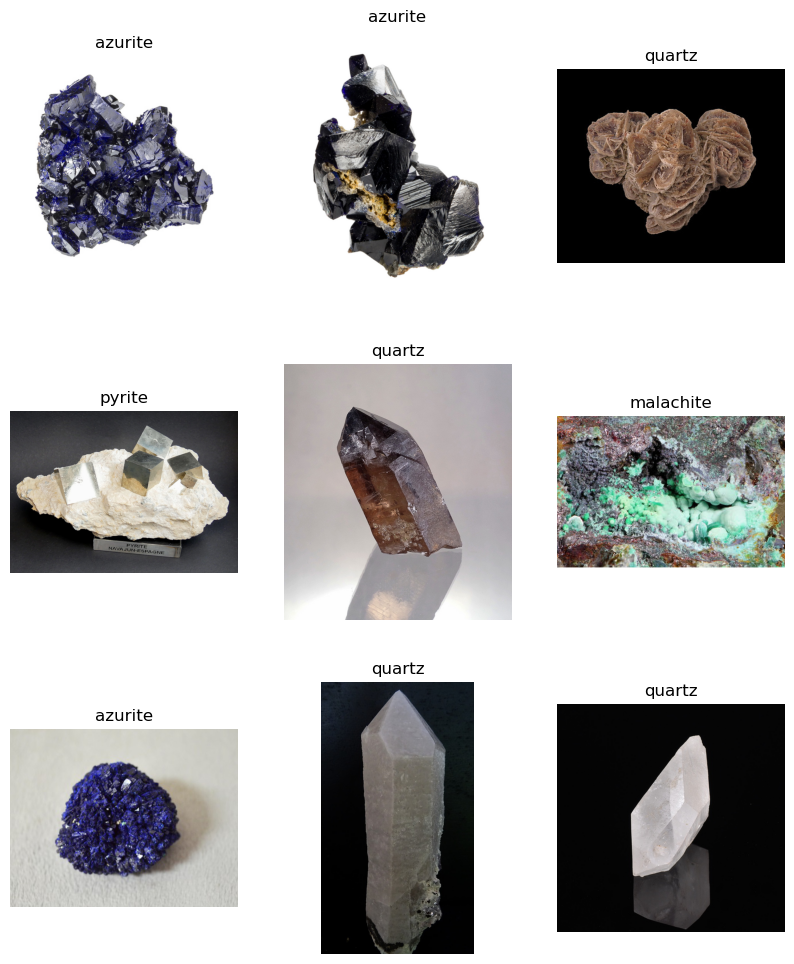

In [12]:
# Plotting 9 random images
import matplotlib.pyplot as plt
import random
from PIL import Image
# 1. Define new data path
data_20_percent = data_20_percent
# 2. Create list of image paths
images_paths_list = list(data_20_percent.glob("*/*/*"))
# 3. Select 9 random image paths
n = 9
random_list = random.sample(images_paths_list, k=n)

# 4. Create figure
plt.figure(figsize=(10, 12))
nrows = 3
ncol = 3
# 5. Plotting
for i, sample in enumerate(random_list):
    # Create subplot
    plt.subplot(nrows, ncol, i + 1)
    # Open image
    img = Image.open(sample)
    # Plot image
    plt.imshow(img)
    plt.title(f"{sample.parent.name}")
    plt.grid(False)
    plt.axis(False)

### 1.3 Creating datasets and dataloaders

In [4]:
# Let's create a function that permits us to create dataloader from data paths
import torch
import torchvision

from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
from pathlib import Path

def create_dataloaders(train_dir: Path,
                       test_dir: Path,
                       transform: torchvision.transforms.Compose,
                       batch_size: int = 32):
    """Function that returns train and test dataloders from train and test data paths.
    Also returns test data to make predictions.
    
    Args:
        train_dir (Path): Path of the training dataset
        test_dir (Path): Path of testing dataset
        transformer (torchvision.transformer): Transformer to apply to datasets
        batch_size (int): batch size. Default to 32.

    Returns:
        A tuple of (train_dataloader, test_dataloader, class_names, test_data)
    """

    # 1. Make sure data paths do exists
    if train_dir.exists() and test_dir.exists():
        pass
    else:
        print(f"[ERROR] {train_dir} or {test_dir} doesn't exits.")
        return
    
    # 2. Create datasets
    train_data = ImageFolder(root=train_dir, transform=transform)
    test_data = ImageFolder(root=test_dir, transform=transform)

    # 3. Get data classes
    class_names = train_data.classes

    # 4. Turn datasets into dataloaders
    train_dataloader = DataLoader(dataset=train_data,
                                  batch_size=batch_size,
                                  shuffle=True,
                                  pin_memory=True)
    test_dataloader = DataLoader(dataset=test_data,
                                 batch_size=batch_size,
                                 shuffle=False,
                                 pin_memory=True)
    
    # 5. Return tuple with results
    return train_dataloader, test_dataloader, class_names, test_data

To start small, as we stated at the beggining, let's setup a simple transformer for our data. Let's call ir "Transform_V1".

In [6]:
# Setup a transform for our data
transform_V1 = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])
transform_V1

Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)

In [ ]:
# Setup train and test dir for 20%
data_path = Path("data_20_percent")
train_dir = data_path / "train"
test_dir = data_path / "test"
# Setup batch size
BATCH_SIZE = 32 

# Create dataloaders
train_dataloader, test_dataloader, class_names, test_data = create_dataloaders(train_dir=train_dir,
                                                                    test_dir=test_dir,
                                                                    transform=transform_V1,
                                                                    batch_size=BATCH_SIZE)
train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x16f768eb940>,
 ['azurite', 'copper', 'malachite', 'pyrite', 'quartz'])

## 02. Creating model

In [5]:
# Setup agnostic device code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

Let's start by creating a simple model and see what happens.

In [12]:
from torch import nn
# Let's start by a simple model
class SimpleModel_V1(nn.Module):
    def __init__(self, input_channels: int, hidden_units: int, output_size: int):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )
        self.linear = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*32*32,
                      out_features=len(class_names),
                      bias=True)
        )

    def forward(self, x):
        return self.linear(self.block1(x))
    
# Create an instance
simple_model_V1 = SimpleModel_V1(input_channels=3, hidden_units=10, output_size=len(class_names)).to(device)
simple_model_V1

SimpleModel_V1(
  (block1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (linear): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=10240, out_features=5, bias=True)
  )
)

## 03. Training Model

Let's setup loss function, optimizer, and an accuracy function to further metrics. As we are working with multi-class classifier, we will use "Cross Entropy Loss" function, and Adam as optimizer to start.

In [13]:
from torchmetrics import Accuracy
# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V1.parameters(),
                             lr=0.001)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

Let's create a function to train this model and any other future model on this project.

In [17]:
from tqdm.auto import tqdm
from torch import nn
from torchmetrics import Metric
from timeit import default_timer as timer

# Let's make the training process a function to replicate
def train(model: nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: nn.Module,
          loss_fn: nn.Module,
          acc_fn: Metric,
          epochs: int):
    
    """Carries the training and testing steps, and returns a Dictionary with train loss and acc, and test loss and acc per epoch
    Args:
        model: Model to train on.
        train_dataloader: Train dataloader
        test_dataloader: Test dataloader
        loss_fn: Loss function
        acc_fn: Accuracy function
        epochs: Number of epochs
    """
    # start the timer
    start_time = timer()

    # Define Epochs
    epochs = epochs
    
    # Create a dictionary to track results
    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []}
    #TRAINING
    model.train()
    for epoch in tqdm(range(epochs)):

        train_loss = 0
        for batch, (X, y) in enumerate(train_dataloader):
            # Send data to device
            X, y = X.to(device), y.to(device)
            # Forward prop
            y_logits = model(X)
            y_preds = torch.softmax(y_logits, dim=1).argmax(dim=1)
            # Calculate loss
            loss = loss_fn(y_logits, y)
            # Update batch loss and acc
            train_loss += loss.item()
            acc_fn(y_preds, y)
            # Gradient to zero
            optimizer.zero_grad()
            # Backward prop
            loss.backward()
            # Update parameters
            optimizer.step()

        # Calculate train loss and acc per epoch
        train_loss /= len(train_dataloader)
        train_acc = acc_fn.compute().item() * 100
        # Reset acc function
        acc_fn.reset()

        # TESTING
        model.eval()
        with torch.inference_mode():
            test_loss = 0
            for X, y in test_dataloader:
                # Data to device
                X, y = X.to(device), y.to(device)
                # Forward prop
                test_logits = model(X)
                test_preds = torch.softmax(test_logits, dim=1).argmax(dim=1)
                # Calculate loss
                loss = loss_fn(test_logits, y)
                # Update loss and acc
                test_loss += loss.item()
                acc_fn(test_preds, y)

            # Calculate test loss and acc per epoch
            test_loss /= len(test_dataloader)
            test_acc = acc_fn.compute().item() * 100

        # Update results tracking
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

        # Print out what's happening
        print(f"Epoch: {epoch} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")
        # Reset acc function
        acc_fn.reset()

    print(f"Job DONE! Training carried out in {epochs} epochs")

    # End timer
    end_time = timer()
    total_time = end_time - start_time
    print(f"Total Training time: {total_time:.3f} seconds")

    return results

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 1.1818 | Train Acc: 57.50% | Test Loss: 0.9576 | Test Acc: 67.03%
Epoch: 1 | Train Loss: 0.9943 | Train Acc: 63.08% | Test Loss: 0.8022 | Test Acc: 70.88%
Epoch: 2 | Train Loss: 0.8297 | Train Acc: 68.83% | Test Loss: 0.7740 | Test Acc: 71.55%
Epoch: 3 | Train Loss: 0.7266 | Train Acc: 73.07% | Test Loss: 0.7328 | Test Acc: 73.32%
Epoch: 4 | Train Loss: 0.6518 | Train Acc: 75.96% | Test Loss: 0.7041 | Test Acc: 74.97%
Job DONE! Training carried out in 5 epochs


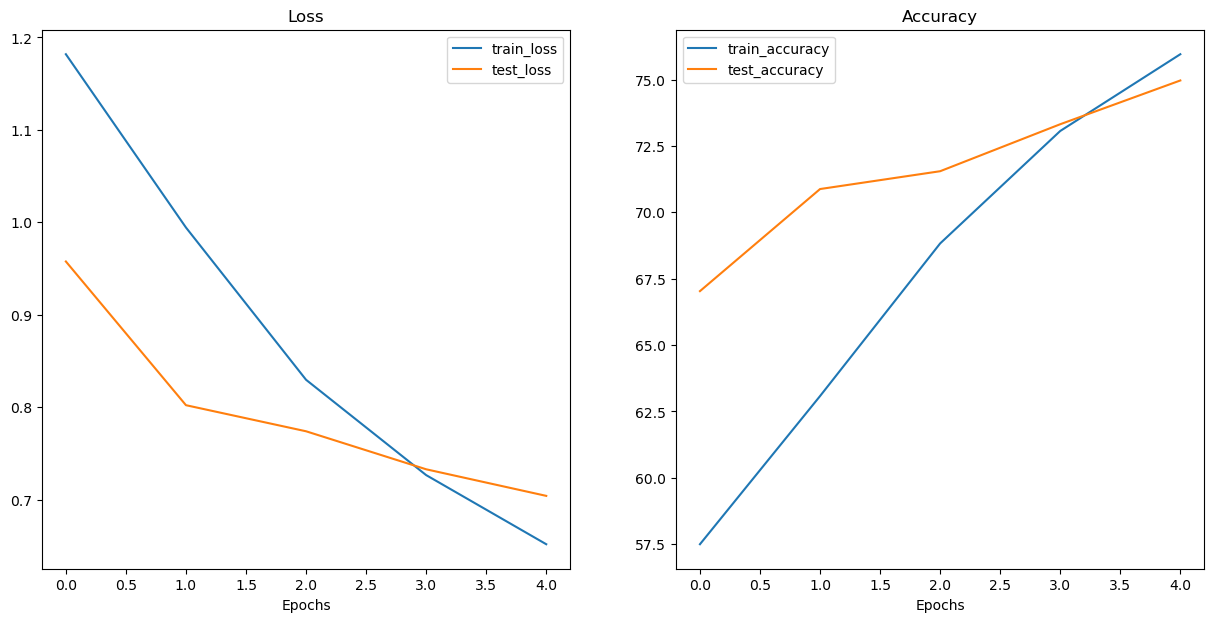

In [16]:
from helper_function.helper_functions import plot_loss_curves
# Let's train the model V2
results = train(model=simple_model_V1,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=5)

plot_loss_curves(results)

Almost 75% on test accuracy. Not bad. However, we can see that the model started to overfit on the 5th epoch. 
Now, basing on the [VGG model](https://poloclub.github.io/cnn-explainer/), we will deeper our model by adding another convolutional block, and keeping the amount of hidden layers.

### Creating Model V2

In [27]:
from torch import nn
# Let's start by a simple model
class SimpleModel_V2(nn.Module):
    def __init__(self, input_channels: int, hidden_units: int, output_size: int):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.linear = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*16*16,
                      out_features=len(class_names),
                      bias=True)
        )

    def forward(self, x):
        return self.linear(self.block2(self.block1(x)))
    
# Create an instance
simple_model_V2 = SimpleModel_V2(input_channels=3, hidden_units=10, output_size=len(class_names)).to(device)
simple_model_V2

SimpleModel_V2(
  (block1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (linear): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=5, bias=True)
  )
)

In [28]:
from torchmetrics import Accuracy
# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V2.parameters(),
                             lr=0.001)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 1.2935 | Train Acc: 55.45% | Test Loss: 1.1003 | Test Acc: 63.06%
Epoch: 1 | Train Loss: 1.1856 | Train Acc: 55.58% | Test Loss: 1.0184 | Test Acc: 59.52%
Epoch: 2 | Train Loss: 1.0393 | Train Acc: 61.13% | Test Loss: 0.9521 | Test Acc: 68.01%
Epoch: 3 | Train Loss: 0.9839 | Train Acc: 62.34% | Test Loss: 0.9289 | Test Acc: 60.56%
Epoch: 4 | Train Loss: 0.9273 | Train Acc: 64.22% | Test Loss: 0.7846 | Test Acc: 71.55%
Job DONE! Training carried out in 5 epochs
Total Training time: 272.051 seconds


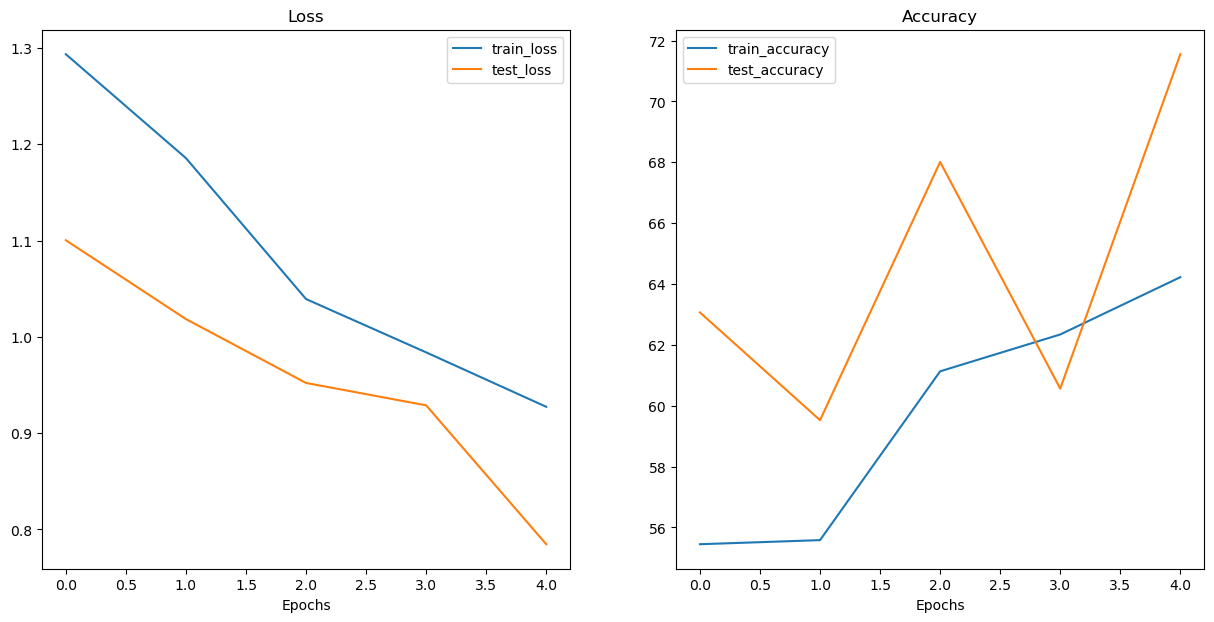

In [29]:
# Let's train the model V2
results = train(model=simple_model_V2,
      train_dataloader=train_dataloader,
      test_dataloader=test_dataloader,
      optimizer=optimizer,
      loss_fn=loss_fn,
      acc_fn=acc_fn,
      epochs=5)

plot_loss_curves(results)

It didn''t go better than the first model. However, it didn't show overfitting in this case. Let's train ir for 5 more epochs and see what happens.

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 0.8577 | Train Acc: 67.62% | Test Loss: 0.7580 | Test Acc: 72.77%
Epoch: 1 | Train Loss: 0.8161 | Train Acc: 68.49% | Test Loss: 0.7410 | Test Acc: 73.14%
Epoch: 2 | Train Loss: 0.7920 | Train Acc: 69.44% | Test Loss: 0.7309 | Test Acc: 72.83%
Epoch: 3 | Train Loss: 0.7857 | Train Acc: 69.47% | Test Loss: 0.7368 | Test Acc: 74.30%
Epoch: 4 | Train Loss: 0.7548 | Train Acc: 70.58% | Test Loss: 0.7112 | Test Acc: 74.79%
Job DONE! Training carried out in 5 epochs
Total Training time: 268.256 seconds


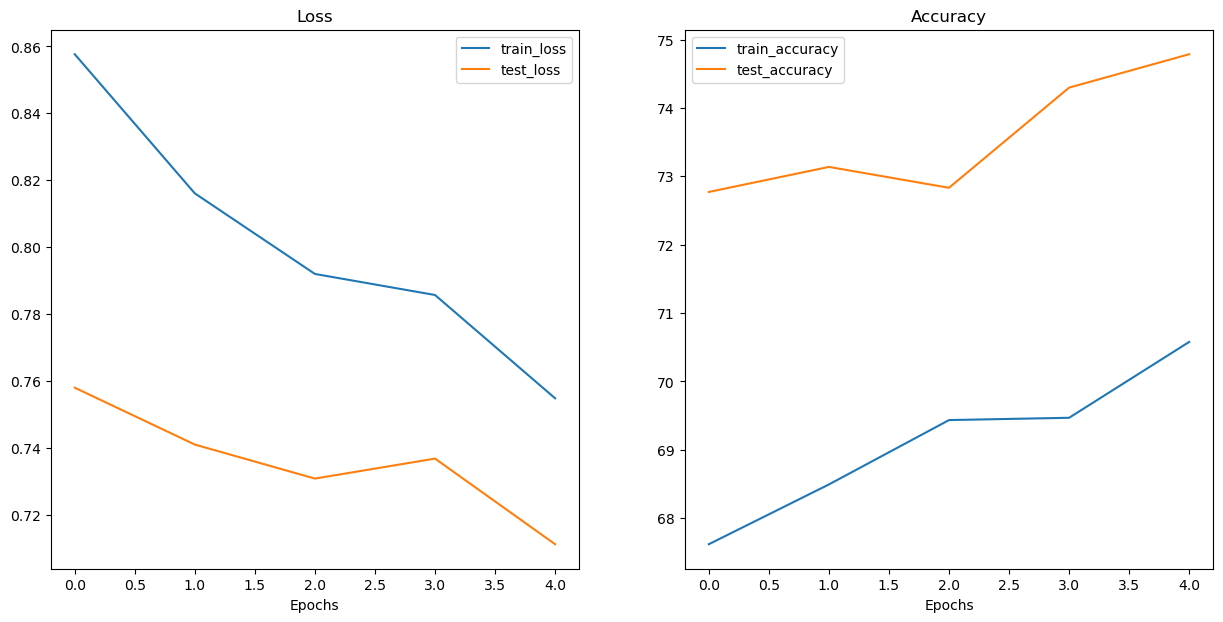

In [30]:
# Let's train the model V2
results = train(model=simple_model_V2,
      train_dataloader=train_dataloader,
      test_dataloader=test_dataloader,
      optimizer=optimizer,
      loss_fn=loss_fn,
      acc_fn=acc_fn,
      epochs=5)

plot_loss_curves(results)

**Simple Model V2** reached almost the same test accuracy than the V1, but in 5 more epochs. However, now the model doesn't overfit.
Now, let's see how Simple model but deeper performs.

### Creating model V3

In [31]:
from torch import nn
# Let's start by a simple model
class SimpleModel_V3(nn.Module):
    def __init__(self, input_channels: int, hidden_units: int, output_size: int):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.linear = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*32*32,
                      out_features=len(class_names),
                      bias=True)
        )

    def forward(self, x):
        return self.linear((self.block1(x)))
    
# Create an instance
simple_model_V1_deeper = SimpleModel_V3(input_channels=3, hidden_units=15, output_size=len(class_names)).to(device)
simple_model_V1_deeper

SimpleModel_V3(
  (block1): Sequential(
    (0): Conv2d(3, 15, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(15, 15, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (linear): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=15360, out_features=5, bias=True)
  )
)

In [34]:
from torchmetrics import Accuracy
# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V1_deeper.parameters(),
                             lr=0.001)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
train(model=simple_model_V1_deeper,
      train_dataloader=train_dataloader,
      test_dataloader=test_dataloader,
      optimizer=optimizer,
      loss_fn=loss_fn,
      acc_fn=acc_fn,
      epochs=5)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 1.1740 | Train Acc: 57.73% | Test Loss: 0.8867 | Test Acc: 70.15%
Epoch: 1 | Train Loss: 0.9281 | Train Acc: 65.94% | Test Loss: 0.8525 | Test Acc: 69.47%
Epoch: 2 | Train Loss: 0.8349 | Train Acc: 68.09% | Test Loss: 0.7601 | Test Acc: 71.49%
Epoch: 3 | Train Loss: 0.7405 | Train Acc: 71.96% | Test Loss: 0.7671 | Test Acc: 74.97%
Epoch: 4 | Train Loss: 0.6512 | Train Acc: 76.33% | Test Loss: 0.6708 | Test Acc: 76.56%
Job DONE! Training carried out in 5 epochs
Total Training time: 272.512 seconds


{'train_loss': [1.1740019193259619,
  0.9280673899958211,
  0.8349438860852231,
  0.7405165898543532,
  0.6512289418969103],
 'train_acc': [57.73369073867798,
  65.93813300132751,
  68.09011697769165,
  71.95696234703064,
  76.3281762599945],
 'test_loss': [0.8867331279011873,
  0.8524866356299474,
  0.7601337656378746,
  0.7671278568987663,
  0.6707934659834092],
 'test_acc': [70.14651894569397,
  69.47497129440308,
  71.48962020874023,
  74.96947646141052,
  76.55677795410156]}

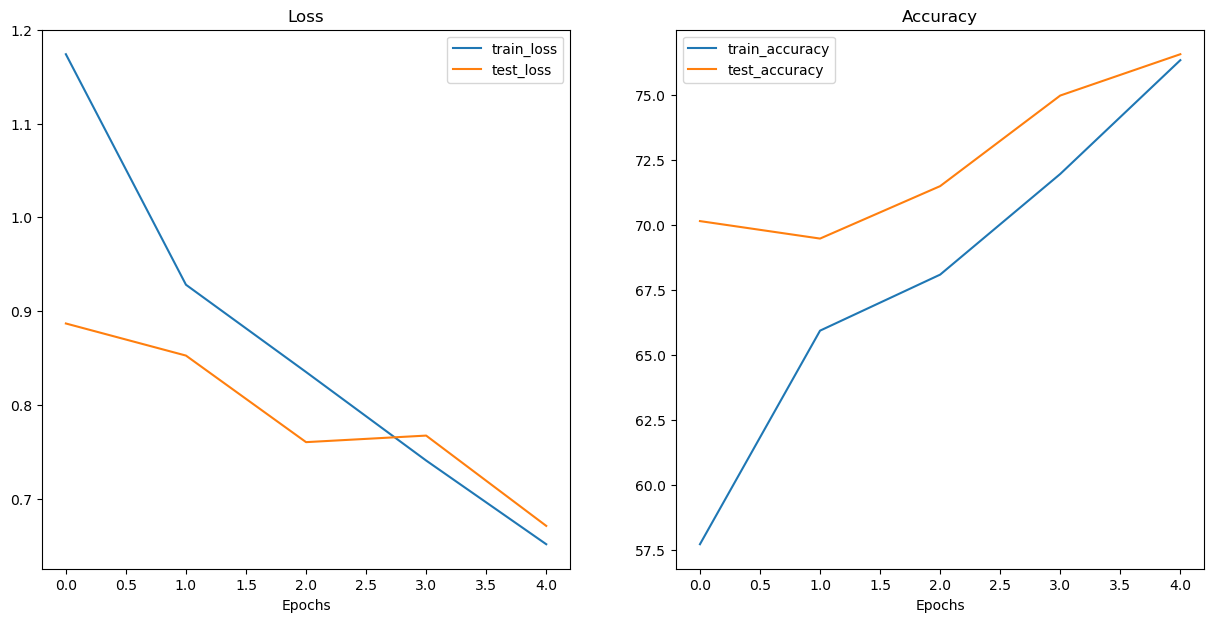

In [35]:
results = {'train_loss': [1.1740019193259619,
  0.9280673899958211,
  0.8349438860852231,
  0.7405165898543532,
  0.6512289418969103],
 'train_acc': [57.73369073867798,
  65.93813300132751,
  68.09011697769165,
  71.95696234703064,
  76.3281762599945],
 'test_loss': [0.8867331279011873,
  0.8524866356299474,
  0.7601337656378746,
  0.7671278568987663,
  0.6707934659834092],
 'test_acc': [70.14651894569397,
  69.47497129440308,
  71.48962020874023,
  74.96947646141052,
  76.55677795410156]}
plot_loss_curves(results)

It improved by almost 1%. However, it seems to be starting to overfit again.
Conclusion: let's keep the architecture with 2 convolutional layers and continue tuning it.
Now, let's try making the model deeper and applying a pyramidal structure.

In [36]:
from torch import nn
# Let's start by a simple model
class SimpleModel_V4(nn.Module):
    def __init__(self, input_channels: int, output_size: int):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=64,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=64,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=32,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU()
        )

        self.linear = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=32*32*32,
                      out_features=output_size,
                      bias=True)
        )

    def forward(self, x):
        return self.linear(self.block2(self.block1(x)))
    
# Create an instance
simple_model_V2_deeper = SimpleModel_V4(input_channels=3, output_size=len(class_names)).to(device)
simple_model_V2_deeper

SimpleModel_V4(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (linear): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=5, bias=True)
  )
)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 1.1706 | Train Acc: 58.07% | Test Loss: 0.9157 | Test Acc: 68.38%
Epoch: 1 | Train Loss: 0.9810 | Train Acc: 64.63% | Test Loss: 0.8658 | Test Acc: 71.98%
Epoch: 2 | Train Loss: 0.8767 | Train Acc: 68.19% | Test Loss: 0.7690 | Test Acc: 73.57%
Epoch: 3 | Train Loss: 0.8156 | Train Acc: 70.21% | Test Loss: 0.7147 | Test Acc: 75.58%
Epoch: 4 | Train Loss: 0.7591 | Train Acc: 71.22% | Test Loss: 0.7471 | Test Acc: 73.57%
Job DONE! Training carried out in 5 epochs
Total Training time: 304.055 seconds


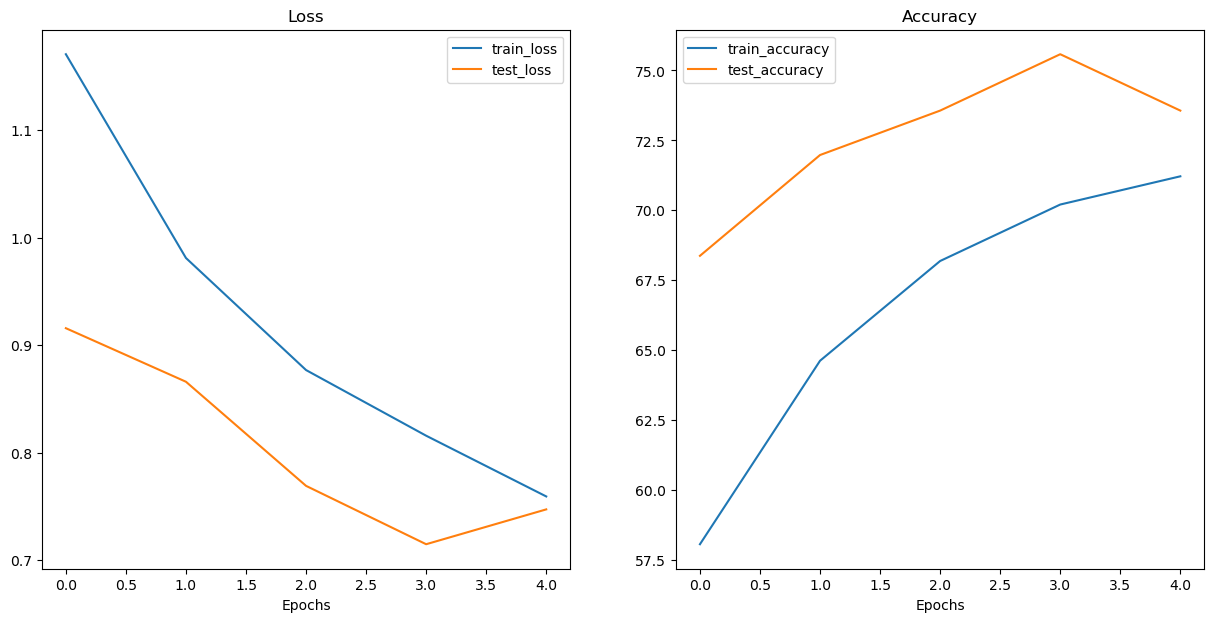

In [38]:
from torchmetrics import Accuracy
# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V2_deeper.parameters(),
                             lr=0.001)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V2_deeper,
                  train_dataloader=train_dataloader,
                  test_dataloader=test_dataloader,
                  optimizer=optimizer,
                  loss_fn=loss_fn,
                  acc_fn=acc_fn,
                  epochs=5)
plot_loss_curves(results)

The model seems to start to overfit. Let's train it for 2 more epochs and see what happens.

  0%|          | 0/2 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 0.7075 | Train Acc: 73.13% | Test Loss: 0.6703 | Test Acc: 77.29%
Epoch: 1 | Train Loss: 0.6222 | Train Acc: 76.73% | Test Loss: 0.6600 | Test Acc: 76.37%
Job DONE! Training carried out in 2 epochs
Total Training time: 116.579 seconds


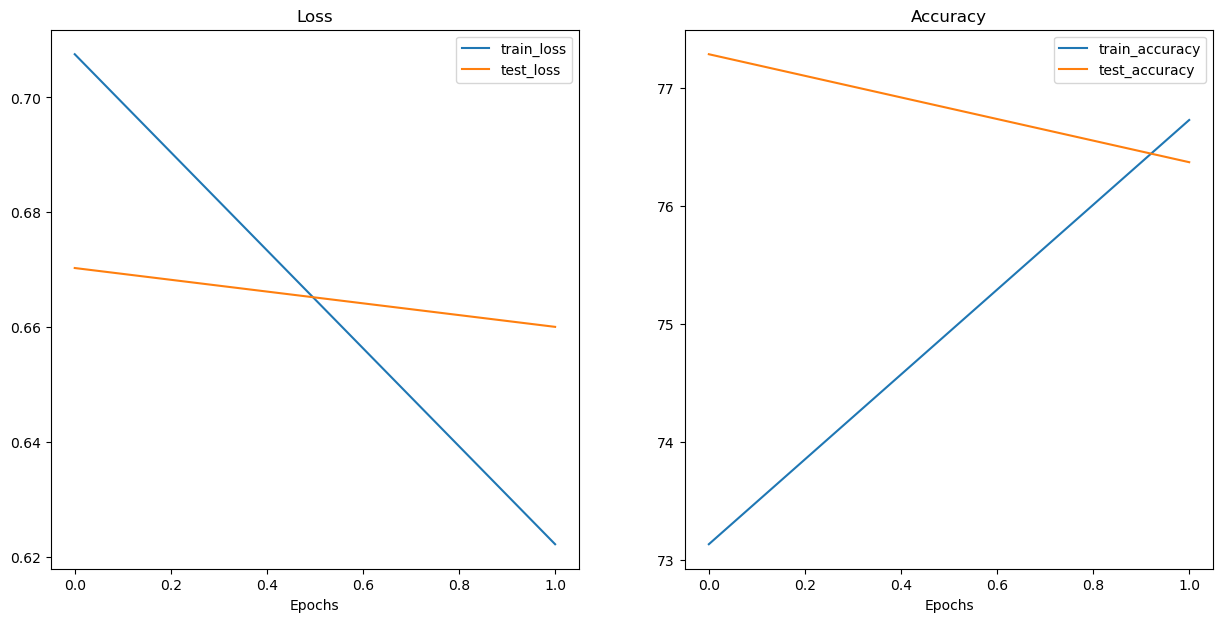

In [39]:
# Let's train the model V2
results = train(model=simple_model_V2_deeper,
                  train_dataloader=train_dataloader,
                  test_dataloader=test_dataloader,
                  optimizer=optimizer,
                  loss_fn=loss_fn,
                  acc_fn=acc_fn,
                  epochs=2)
plot_loss_curves(results)

The model is overfitting. To handle that, let's try adding dropout.

In [42]:
from torch import nn
# Let's start by a simple model
class SimpleModel_V5_dropout(nn.Module):
    def __init__(self, input_channels: int, output_size: int, dropout: float):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=64,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=64,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=32,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU()
        )

        self.linear = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(in_features=32*32*32,
                      out_features=output_size,
                      bias=True)
        )

    def forward(self, x):
        return self.linear(self.block2(self.block1(x)))
    
# Create an instance
simple_model_V1_dropout = SimpleModel_V5_dropout(input_channels=3, output_size=len(class_names), dropout=0.1).to(device)
simple_model_V1_dropout

SimpleModel_V5_dropout(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (linear): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.1, inplace=False)
    (2): Linear(in_features=32768, out_features=5, bias=True)
  )
)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 1.2248 | Train Acc: 55.88% | Test Loss: 0.9470 | Test Acc: 66.97%
Epoch: 1 | Train Loss: 0.9955 | Train Acc: 64.09% | Test Loss: 0.8485 | Test Acc: 72.22%
Epoch: 2 | Train Loss: 0.8924 | Train Acc: 68.29% | Test Loss: 0.8190 | Test Acc: 72.47%
Epoch: 3 | Train Loss: 0.8422 | Train Acc: 68.59% | Test Loss: 0.7527 | Test Acc: 73.81%
Epoch: 4 | Train Loss: 0.8068 | Train Acc: 69.84% | Test Loss: 0.7912 | Test Acc: 74.54%
Epoch: 5 | Train Loss: 0.7721 | Train Acc: 70.85% | Test Loss: 0.7397 | Test Acc: 74.24%
Epoch: 6 | Train Loss: 0.7427 | Train Acc: 71.59% | Test Loss: 0.7037 | Test Acc: 75.27%
Epoch: 7 | Train Loss: 0.7084 | Train Acc: 73.10% | Test Loss: 0.7190 | Test Acc: 75.76%
Epoch: 8 | Train Loss: 0.6891 | Train Acc: 73.20% | Test Loss: 0.7311 | Test Acc: 75.21%
Epoch: 9 | Train Loss: 0.6311 | Train Acc: 75.76% | Test Loss: 0.7579 | Test Acc: 75.76%
Job DONE! Training carried out in 10 epochs
Total Training time: 610.615 seconds


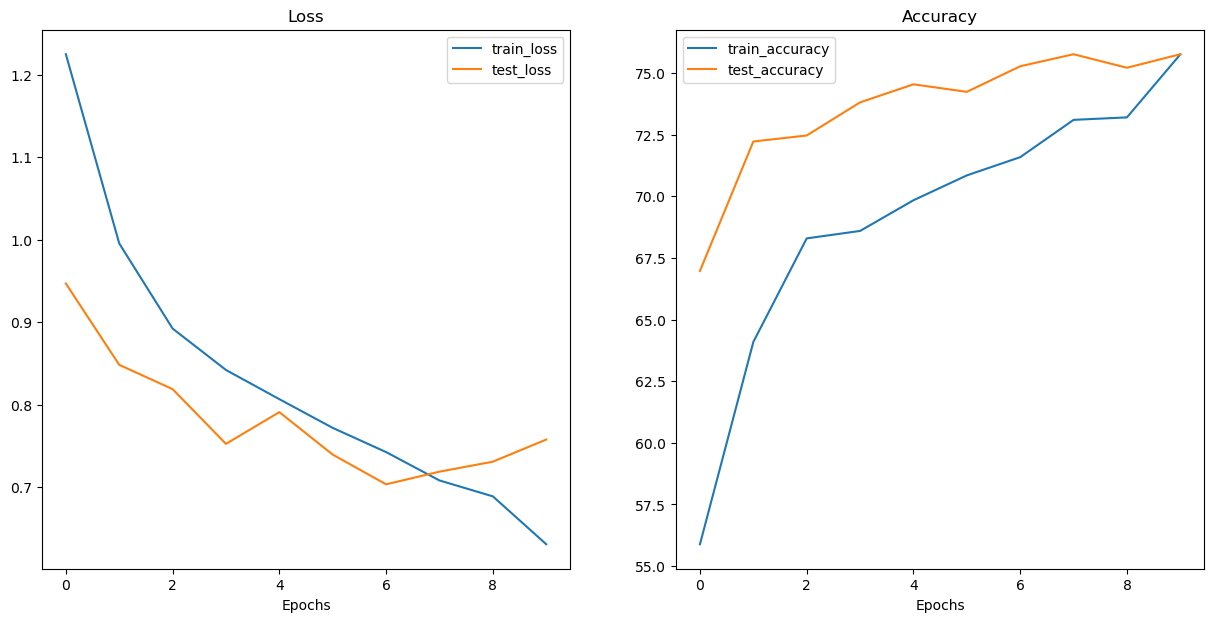

In [43]:
from torchmetrics import Accuracy
# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V1_dropout.parameters(),
                             lr=0.001)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V1_dropout,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=10)

plot_loss_curves(results)

It's seem liek the model is reaching its ceiling of 75% of accuracy in testing, and it start to overfit in epoch 7. Let's try increasing dropout.

In [44]:
# Create an instance
simple_model_V2_dropout = SimpleModel_V5_dropout(input_channels=3, output_size=len(class_names), dropout=0.2).to(device)
simple_model_V2_dropout

SimpleModel_V5_dropout(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (linear): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.2, inplace=False)
    (2): Linear(in_features=32768, out_features=5, bias=True)
  )
)

  0%|          | 0/8 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 1.1943 | Train Acc: 56.62% | Test Loss: 0.8924 | Test Acc: 67.03%
Epoch: 1 | Train Loss: 0.9375 | Train Acc: 65.64% | Test Loss: 0.8308 | Test Acc: 71.25%
Epoch: 2 | Train Loss: 0.8643 | Train Acc: 67.42% | Test Loss: 0.7480 | Test Acc: 72.83%
Epoch: 3 | Train Loss: 0.7940 | Train Acc: 68.66% | Test Loss: 0.7303 | Test Acc: 74.66%
Epoch: 4 | Train Loss: 0.7400 | Train Acc: 71.49% | Test Loss: 0.6796 | Test Acc: 76.62%
Epoch: 5 | Train Loss: 0.7140 | Train Acc: 72.86% | Test Loss: 0.6558 | Test Acc: 76.68%
Epoch: 6 | Train Loss: 0.6576 | Train Acc: 75.49% | Test Loss: 0.7144 | Test Acc: 76.01%
Epoch: 7 | Train Loss: 0.6386 | Train Acc: 75.69% | Test Loss: 0.6227 | Test Acc: 79.30%
Job DONE! Training carried out in 8 epochs
Total Training time: 484.046 seconds


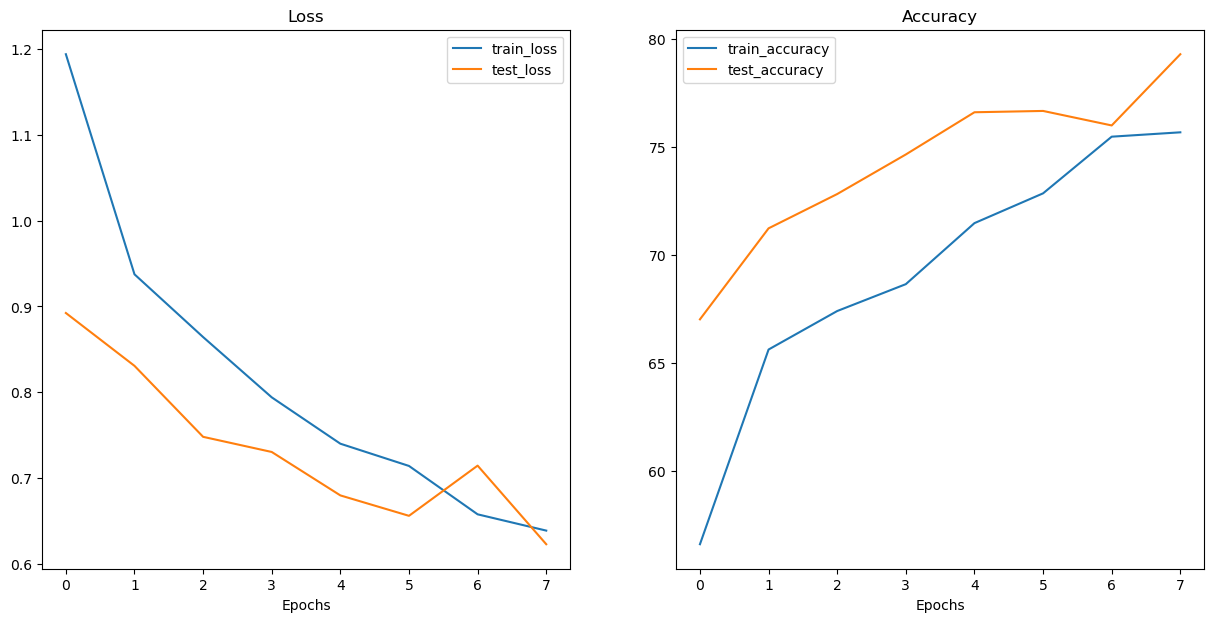

In [46]:
from torchmetrics import Accuracy
# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V2_dropout.parameters(),
                             lr=0.001)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V2_dropout,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=8)

plot_loss_curves(results)

Overfitting improved! However, the testing curves don't look as smooth as we would like. Now, let's apply data agumentation to try to improve overfitting.

In [47]:
# Define new transform
transform_V2 = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor()
])

# Create new dataloaders
train_dataloader, test_dataloader, class_names, test_data = create_dataloaders(train_dir=train_dir,
                                                                    test_dir=test_dir,
                                                                    transform=transform_V2,
                                                                    batch_size=32)
train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x16f58e5f2b0>,
 ['azurite', 'copper', 'malachite', 'pyrite', 'quartz'])

Let's train the same model, but this time with the new dataloaders.

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 1.2525 | Train Acc: 55.62% | Test Loss: 1.0028 | Test Acc: 64.59%
Epoch: 1 | Train Loss: 1.0847 | Train Acc: 60.19% | Test Loss: 0.9749 | Test Acc: 64.53%
Epoch: 2 | Train Loss: 0.9974 | Train Acc: 64.09% | Test Loss: 0.8702 | Test Acc: 69.41%
Epoch: 3 | Train Loss: 0.9678 | Train Acc: 64.79% | Test Loss: 0.8442 | Test Acc: 70.33%
Epoch: 4 | Train Loss: 0.9238 | Train Acc: 65.94% | Test Loss: 0.8629 | Test Acc: 69.66%
Epoch: 5 | Train Loss: 0.9337 | Train Acc: 63.89% | Test Loss: 0.9721 | Test Acc: 66.42%
Epoch: 6 | Train Loss: 0.9322 | Train Acc: 66.21% | Test Loss: 0.8311 | Test Acc: 70.39%
Epoch: 7 | Train Loss: 0.9035 | Train Acc: 66.98% | Test Loss: 0.7804 | Test Acc: 71.43%
Epoch: 8 | Train Loss: 0.8794 | Train Acc: 68.80% | Test Loss: 0.8149 | Test Acc: 71.92%
Epoch: 9 | Train Loss: 0.8297 | Train Acc: 69.91% | Test Loss: 0.7690 | Test Acc: 72.95%
Job DONE! Training carried out in 10 epochs
Total Training time: 634.221 seconds


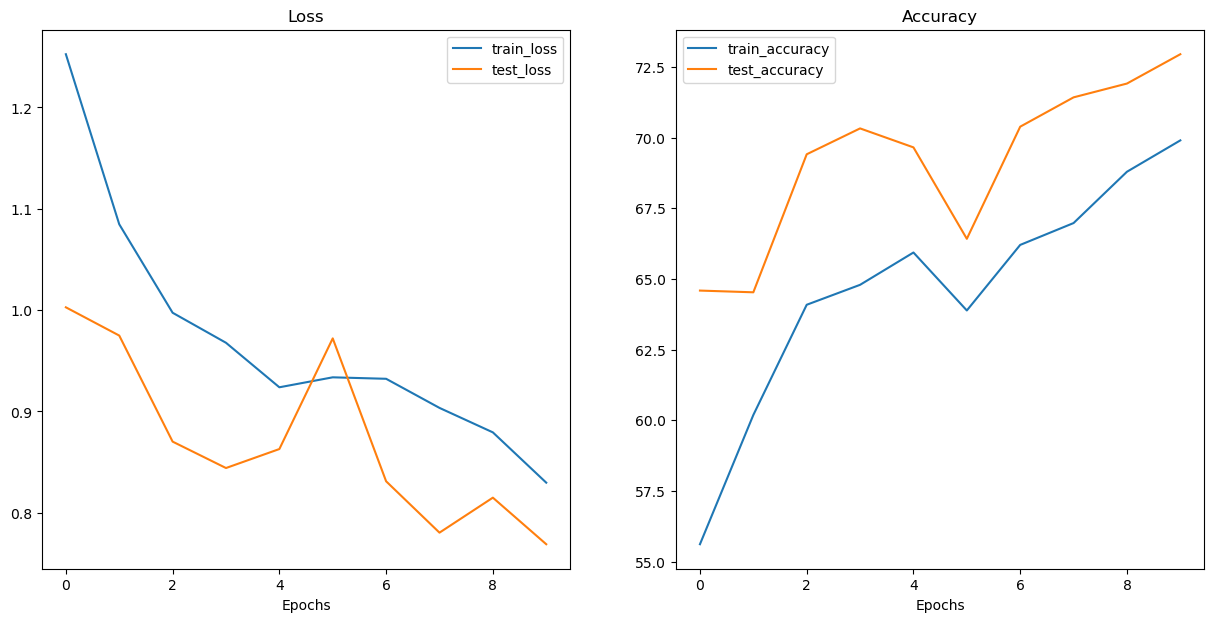

In [48]:
# Train again model but with Data Augmentation
# Recreate the instanceagain
simple_model_V2_dropout = SimpleModel_V5_dropout(input_channels=3, output_size=len(class_names), dropout=0.2).to(device)

# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V2_dropout.parameters(),
                             lr=0.001)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V2_dropout,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=10)

plot_loss_curves(results)

Wow! Overfitting desapeared! However, it's taking much time to learn now.

To improve convergence, let's add BatchNorm to our model and add a AVGPool to decrease number of parameters.

In [50]:
# Let's create a new model, but this time with dropout in the classifier head
from torch import nn
# Let's start by a simple model
class SimpleModel_V6_dropout_batchnorm_avgpool(nn.Module):
    def __init__(self, input_channels: int, output_size: int, dropout: float):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels=64,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=64,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        self.linear = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(in_features=32,
                      out_features=output_size,
                      bias=True)
        )

    def forward(self, x):
        return self.linear(self.avgpool(self.block2(self.block1(x))))
    
# Create an instance
simple_model_V3_dropout_batchnorm_avgpool = SimpleModel_V6_dropout_batchnorm_avgpool(input_channels=3, output_size=len(class_names), dropout=0.2).to(device)
simple_model_V3_dropout_batchnorm_avgpool

SimpleModel_V6_dropout_batchnorm_avgpool(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): Ad

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 1.2096 | Train Acc: 56.62% | Test Loss: 1.0173 | Test Acc: 66.67%
Epoch: 1 | Train Loss: 1.0762 | Train Acc: 61.47% | Test Loss: 0.9688 | Test Acc: 67.16%
Epoch: 2 | Train Loss: 1.0403 | Train Acc: 63.11% | Test Loss: 0.9352 | Test Acc: 68.80%
Epoch: 3 | Train Loss: 0.9881 | Train Acc: 63.92% | Test Loss: 0.8458 | Test Acc: 71.79%
Epoch: 4 | Train Loss: 1.0047 | Train Acc: 64.29% | Test Loss: 0.9180 | Test Acc: 70.21%
Epoch: 5 | Train Loss: 0.9602 | Train Acc: 65.57% | Test Loss: 0.8674 | Test Acc: 68.62%
Epoch: 6 | Train Loss: 0.9568 | Train Acc: 65.74% | Test Loss: 0.8651 | Test Acc: 70.45%
Epoch: 7 | Train Loss: 0.9069 | Train Acc: 67.89% | Test Loss: 0.8395 | Test Acc: 72.53%
Epoch: 8 | Train Loss: 0.9137 | Train Acc: 67.82% | Test Loss: 0.7910 | Test Acc: 72.04%
Epoch: 9 | Train Loss: 0.8736 | Train Acc: 68.56% | Test Loss: 0.7504 | Test Acc: 75.52%
Job DONE! Training carried out in 10 epochs
Total Training time: 625.106 seconds


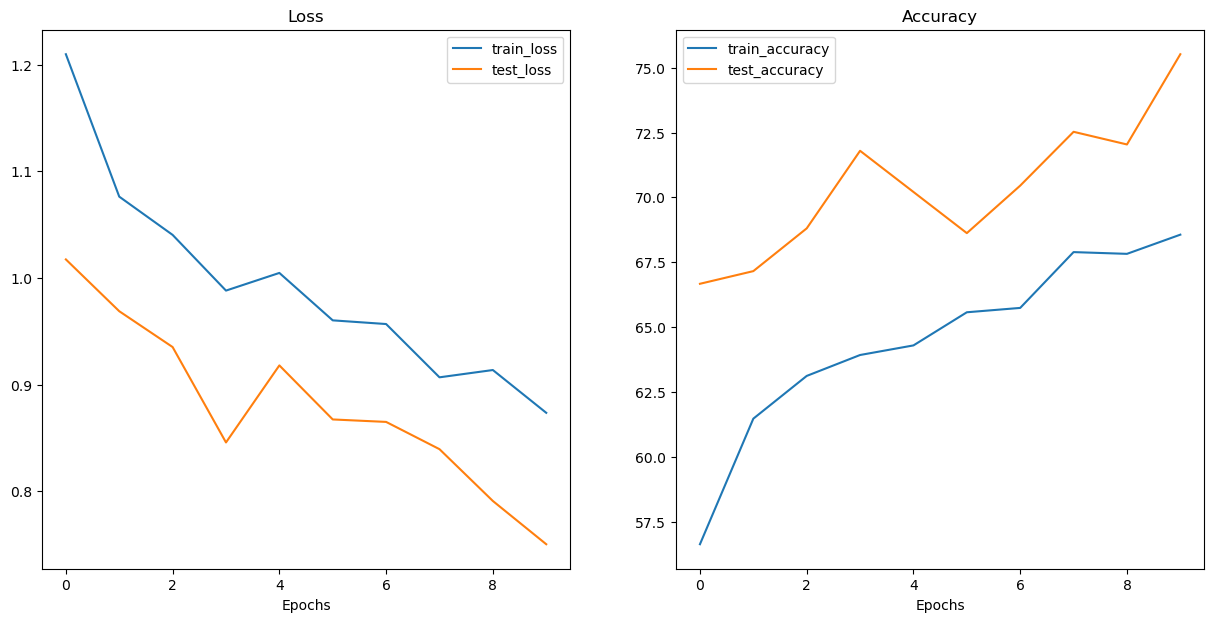

In [51]:
# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V3_dropout_batchnorm_avgpool.parameters(),
                             lr=0.001)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V3_dropout_batchnorm_avgpool,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=10)

plot_loss_curves(results)

Overfitting is solved, for now. However, the model is not learning enough. To improve this, let's add another convolutional block.

Let's now to normalize our data also, to improve learning.

In [68]:
# Let's find the mean and std of our data to then normalize it
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Load data without normalization
normal_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(data_path, transform=normal_transform)
loader = DataLoader(dataset, batch_size=32, shuffle=False)

# 2. Accumulate mean and std per batch
mean =[]
std = []

for images, _ in loader:
    # Images shape: (B, C, H, W)
    batch_mean = images.mean(dim=[0, 2, 3])
    batch_std = images.std(dim=[0, 2, 3])

    mean.append(batch_mean)
    std.append(batch_std)

# 3. Final mean and std
mean = torch.stack(mean).mean(dim=0)
std = torch.stack(std).mean(dim=0)

print(f"Dataset mean: {mean}\n")
print(f"Dataset std: {std}")

Dataset mean: tensor([0.4142, 0.3962, 0.3751])

Dataset std: tensor([0.3079, 0.2997, 0.2949])


In [53]:
# Let's create a new transformer with these values to normalize our datasets
transform_V3 = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.TrivialAugmentWide( num_magnitude_bins=31),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4142, 0.3962, 0.3751],
                         std=[0.3079, 0.2997, 0.2949])
])

# Create new dataloaders
train_dataloader, test_dataloader, class_names, test_data = create_dataloaders(train_dir=train_dir,
                                                                    test_dir=test_dir,
                                                                    transform=transform_V3,
                                                                    batch_size=32)

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x16f467e1150>,
 ['azurite', 'copper', 'malachite', 'pyrite', 'quartz'])

### Let's try a deeper model

In [54]:
# Let's create a new model, but this time with dropout in the classifier head
from torch import nn
# Let's start by a simple model
class SimpleModel_V7_dropout_batchnorm_avgpool(nn.Module):
    def __init__(self, input_channels: int, output_size: int, dropout: float):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=128,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(in_channels=128,
                      out_channels=128,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=128,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels=64,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(in_channels=64,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        self.linear = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(in_features=32,
                      out_features=output_size,
                      bias=True)
        )

    def forward(self, x):
        return self.linear(self.avgpool(self.block3(self.block2(self.block1(x)))))
    
# Create an instance
simple_model_V4_dropout_batchnorm_avgpool = SimpleModel_V7_dropout_batchnorm_avgpool(input_channels=3, output_size=len(class_names), dropout=0.3).to(device)
simple_model_V4_dropout_batchnorm_avgpool

SimpleModel_V7_dropout_batchnorm_avgpool(
  (block1): Sequential(
    (0): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 1.1743 | Train Acc: 58.31% | Test Loss: 0.9424 | Test Acc: 69.54%
Epoch: 1 | Train Loss: 1.0664 | Train Acc: 62.58% | Test Loss: 0.9404 | Test Acc: 67.83%
Epoch: 2 | Train Loss: 0.9862 | Train Acc: 65.10% | Test Loss: 0.8519 | Test Acc: 71.67%
Epoch: 3 | Train Loss: 0.9686 | Train Acc: 65.43% | Test Loss: 0.8428 | Test Acc: 69.90%
Epoch: 4 | Train Loss: 0.9734 | Train Acc: 65.03% | Test Loss: 0.8919 | Test Acc: 70.09%
Epoch: 5 | Train Loss: 0.9222 | Train Acc: 66.81% | Test Loss: 0.8408 | Test Acc: 70.94%
Epoch: 6 | Train Loss: 0.8926 | Train Acc: 67.99% | Test Loss: 0.7993 | Test Acc: 72.95%
Epoch: 7 | Train Loss: 0.8623 | Train Acc: 68.76% | Test Loss: 0.7414 | Test Acc: 73.81%
Epoch: 8 | Train Loss: 0.8517 | Train Acc: 69.67% | Test Loss: 0.7443 | Test Acc: 74.30%
Epoch: 9 | Train Loss: 0.8557 | Train Acc: 69.37% | Test Loss: 0.7583 | Test Acc: 74.11%
Job DONE! Training carried out in 10 epochs
Total Training time: 616.922 seconds


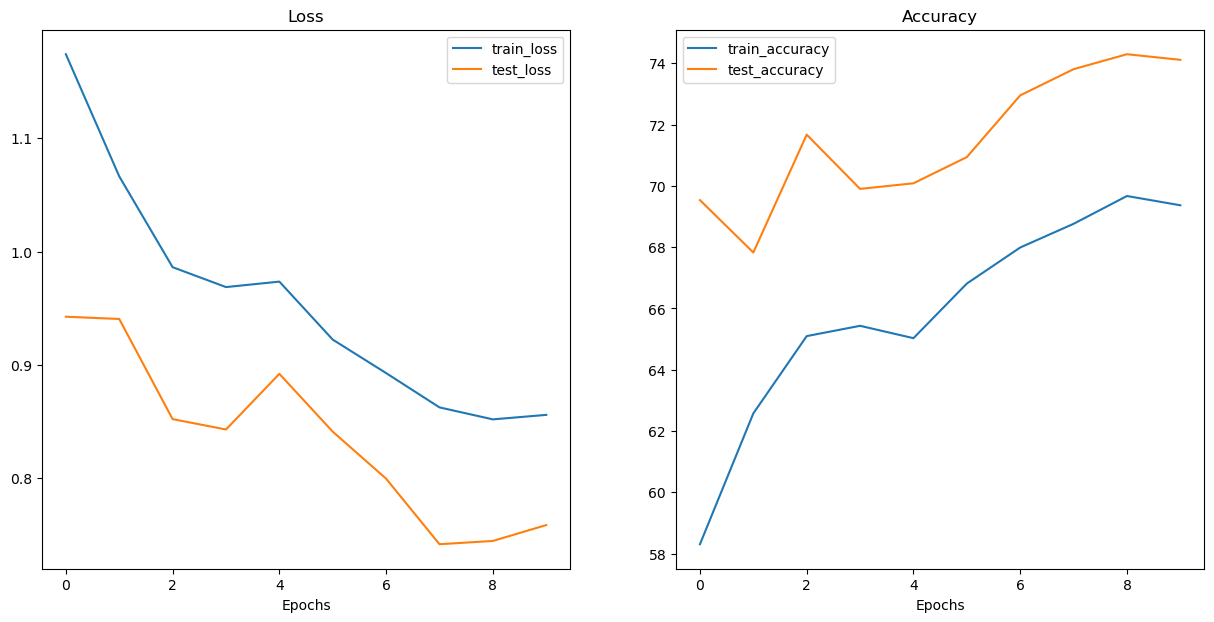

In [55]:
# Now, let's train our best model so far but this time with a normalized dataloader, a dropout of 0.3, and deeper model

# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V4_dropout_batchnorm_avgpool.parameters(),
                             lr=0.001,
                             weight_decay=1e-4)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V4_dropout_batchnorm_avgpool,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=10)

plot_loss_curves(results)

The model is learning properly, but it’s still not learning enough.
Let’s add stronger data augmentation and see how it affects the results.

In [56]:
from torchvision import transforms

# Let's create a new transformer with these values to normalize our datasets
transform_V5 = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4143, 0.3963, 0.3752],
                         std=[0.3151, 0.3071, 0.3022])
])

# Create new dataloaders
train_dataloader, test_dataloader, class_names, test_data = create_dataloaders(train_dir=train_dir,
                                                                    test_dir=test_dir,
                                                                    transform=transform_V5,
                                                                    batch_size=64)

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x16f47425b10>,
 ['azurite', 'copper', 'malachite', 'pyrite', 'quartz'])

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 0.8495 | Train Acc: 69.30% | Test Loss: 0.6933 | Test Acc: 77.05%
Epoch: 1 | Train Loss: 0.7600 | Train Acc: 72.19% | Test Loss: 0.6614 | Test Acc: 77.96%
Epoch: 2 | Train Loss: 0.6991 | Train Acc: 74.95% | Test Loss: 0.6377 | Test Acc: 76.13%
Epoch: 3 | Train Loss: 0.6775 | Train Acc: 75.35% | Test Loss: 0.5659 | Test Acc: 80.71%
Epoch: 4 | Train Loss: 0.6621 | Train Acc: 75.79% | Test Loss: 0.5807 | Test Acc: 81.26%
Epoch: 5 | Train Loss: 0.6326 | Train Acc: 76.66% | Test Loss: 0.6426 | Test Acc: 77.78%
Epoch: 6 | Train Loss: 0.6165 | Train Acc: 77.64% | Test Loss: 0.5795 | Test Acc: 81.20%
Epoch: 7 | Train Loss: 0.6282 | Train Acc: 76.83% | Test Loss: 0.5718 | Test Acc: 81.50%
Epoch: 8 | Train Loss: 0.6143 | Train Acc: 77.27% | Test Loss: 0.5278 | Test Acc: 81.56%
Epoch: 9 | Train Loss: 0.6235 | Train Acc: 77.30% | Test Loss: 0.5823 | Test Acc: 79.43%
Job DONE! Training carried out in 10 epochs
Total Training time: 591.311 seconds


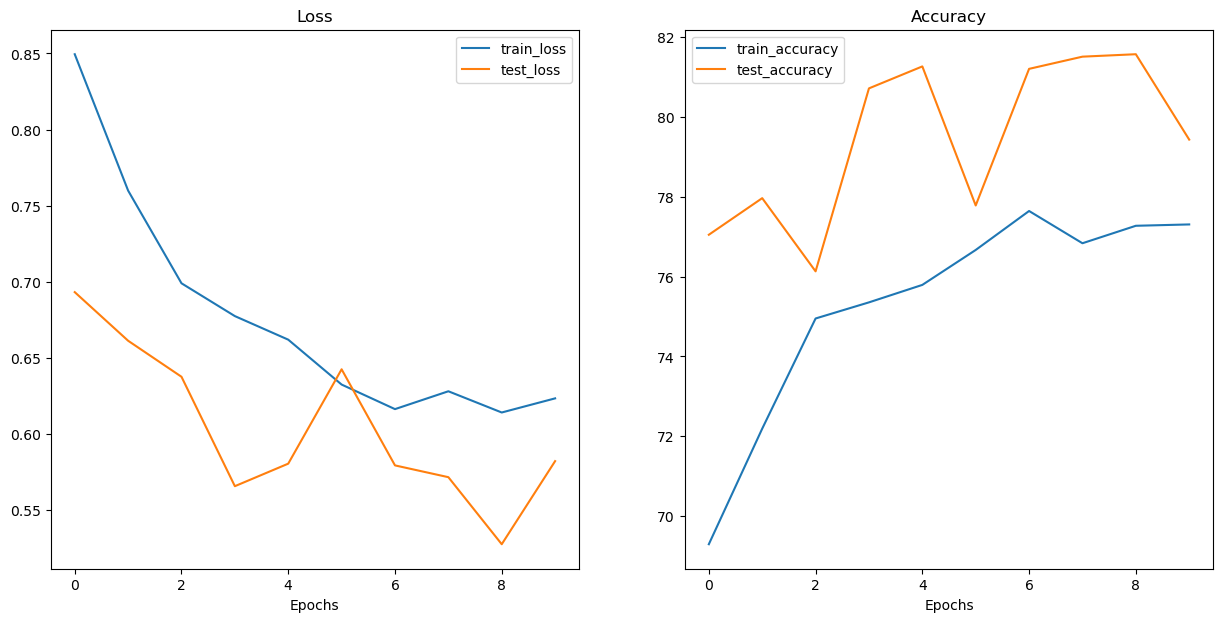

In [57]:
# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=simple_model_V4_dropout_batchnorm_avgpool.parameters(),
                             lr=0.001,
                             weight_decay=1e-4)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V4_dropout_batchnorm_avgpool,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=10)

plot_loss_curves(results)

# Data Augmantation was a huge improvement. Now, let's try to enhance our training function by adding an learning rate SCHEDULER, and see what happens.

In [18]:
from tqdm.auto import tqdm
from torch import nn
from torchmetrics import Metric
import torch

def train(model: nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: nn.Module,
          acc_fn: Metric,
          epochs: int,
          max_lr: float):

    # Create scheduler
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=max_lr,
        steps_per_epoch=len(train_dataloader),
        epochs=epochs,
        pct_start=0.3
    )

    results = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for epoch in tqdm(range(epochs)):
        # -----------------------
        # TRAINING
        # -----------------------
        model.train()
        train_loss = 0
        for X, y in train_dataloader:
            X, y = X.to(device), y.to(device)

            # Forward
            logits = model(X)
            loss = loss_fn(logits, y)

            # Update loss + acc
            train_loss += loss.item()
            preds = logits.argmax(dim=1)
            acc_fn(preds, y)

            # Backprop
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()   

        train_loss /= len(train_dataloader)
        train_acc = acc_fn.compute().item() * 100
        acc_fn.reset()

        # -----------------------
        # TESTING
        # -----------------------
        model.eval()
        test_loss = 0
        with torch.inference_mode():
            for X, y in test_dataloader:
                X, y = X.to(device), y.to(device)

                logits = model(X)
                loss = loss_fn(logits, y)
                test_loss += loss.item()

                preds = logits.argmax(dim=1)
                acc_fn(preds, y)

        test_loss /= len(test_dataloader)
        test_acc = acc_fn.compute().item() * 100
        acc_fn.reset()

        # Log
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

        print(f"Epoch {epoch} | Train Loss: {train_loss:.4f} | Train Acc {train_acc:.2f}% || Test Loss: {test_loss:.4f} | Test Acc {test_acc:.2f}% | LR {scheduler.get_last_lr()[0]:.6f}")

    return results


Let's change also the optimaizer to AdamW for better convergence.

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 0 | Train Loss: 1.1429 | Train Acc 60.69% || Test Loss: 0.8788 | Test Acc 69.66% | LR 0.000849
Epoch 1 | Train Loss: 0.9517 | Train Acc 67.22% || Test Loss: 1.6448 | Test Acc 29.00% | LR 0.002299
Epoch 2 | Train Loss: 0.8868 | Train Acc 69.23% || Test Loss: 1.0036 | Test Acc 62.21% | LR 0.003000
Epoch 3 | Train Loss: 0.8358 | Train Acc 69.57% || Test Loss: 0.7621 | Test Acc 76.13% | LR 0.002845
Epoch 4 | Train Loss: 0.8050 | Train Acc 71.49% || Test Loss: 0.7513 | Test Acc 73.02% | LR 0.002424
Epoch 5 | Train Loss: 0.7764 | Train Acc 72.26% || Test Loss: 0.6749 | Test Acc 75.58% | LR 0.001820
Epoch 6 | Train Loss: 0.7353 | Train Acc 73.47% || Test Loss: 0.6949 | Test Acc 74.11% | LR 0.001152
Epoch 7 | Train Loss: 0.6949 | Train Acc 75.72% || Test Loss: 0.5698 | Test Acc 78.63% | LR 0.000554
Epoch 8 | Train Loss: 0.6702 | Train Acc 76.13% || Test Loss: 0.5465 | Test Acc 81.20% | LR 0.000142
Epoch 9 | Train Loss: 0.6377 | Train Acc 76.43% || Test Loss: 0.5345 | Test Acc 81.26% | LR

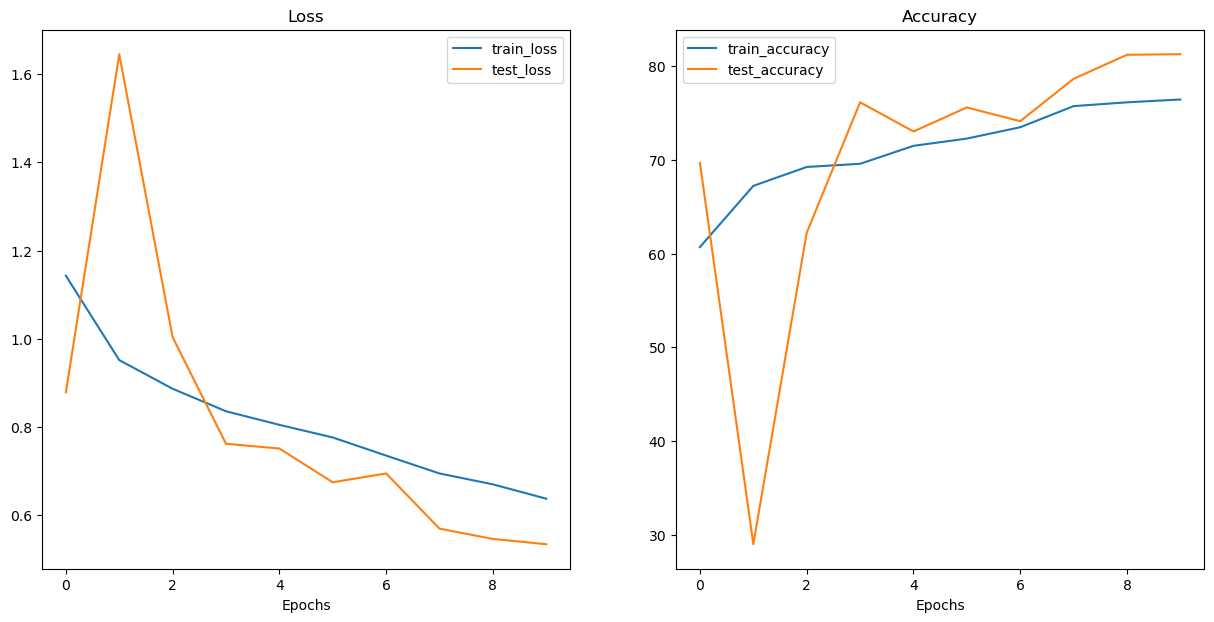

In [59]:
# Create an instance
from helper_function.helper_functions import set_seeds
# Set seeds
set_seeds()
# Create new instance
simple_model_V4_dropout_batchnorm_avgpool = SimpleModel_V7_dropout_batchnorm_avgpool(input_channels=3, output_size=len(class_names), dropout=0.3).to(device)

# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(params=simple_model_V4_dropout_batchnorm_avgpool.parameters(),
                             lr=0.001,
                             weight_decay=1e-4)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V4_dropout_batchnorm_avgpool,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=10,
                max_lr=3e-3)

plot_loss_curves(results)

# Let's imrpove the model now

Let's try to improve our model by adding one more convolutional block, and a linear layer too. Let's see what happens. We hope the model can learn more.

In [60]:
# Let's create a new model, but this time with dropout in the classifier head
from torch import nn
# Let's start by a simple model
class SimpleModel_V8_dropout_batchnorm_avgpool(nn.Module):
    def __init__(self, input_channels: int, output_size: int, dropout: float):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=32,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels=64,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(in_channels=64,
                      out_channels=128,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(in_channels=128,
                      out_channels=128,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block4 = nn.Sequential(
            nn.Conv2d(in_channels=128,
                      out_channels=256,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(in_channels=256,
                      out_channels=256,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(in_features=256,
                      out_features=128,
                      bias=True),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(128, output_size)
        )

    def forward(self, x):
        return self.classifier(self.avgpool(self.block4(self.block3(self.block2(self.block1(x))))))

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 0 | Train Loss: 1.0694 | Train Acc 62.81% || Test Loss: 0.957857567530412 | Test Acc 65.08% | LR 0.000849
Epoch 1 | Train Loss: 0.8553 | Train Acc 69.23% || Test Loss: 1.1923424664598246 | Test Acc 62.52% | LR 0.002299
Epoch 2 | Train Loss: 0.8018 | Train Acc 71.59% || Test Loss: 0.9769105447026399 | Test Acc 63.37% | LR 0.003000
Epoch 3 | Train Loss: 0.7978 | Train Acc 71.89% || Test Loss: 1.9451096545045192 | Test Acc 29.67% | LR 0.002845
Epoch 4 | Train Loss: 0.7409 | Train Acc 72.97% || Test Loss: 0.6981735430084742 | Test Acc 75.40% | LR 0.002424
Epoch 5 | Train Loss: 0.6722 | Train Acc 76.23% || Test Loss: 0.5851116456951087 | Test Acc 80.04% | LR 0.001820
Epoch 6 | Train Loss: 0.6518 | Train Acc 76.03% || Test Loss: 0.49570221167344314 | Test Acc 83.03% | LR 0.001152
Epoch 7 | Train Loss: 0.6222 | Train Acc 77.44% || Test Loss: 0.4677014717688927 | Test Acc 83.33% | LR 0.000554
Epoch 8 | Train Loss: 0.5765 | Train Acc 79.29% || Test Loss: 0.4513646630713573 | Test Acc 83.9

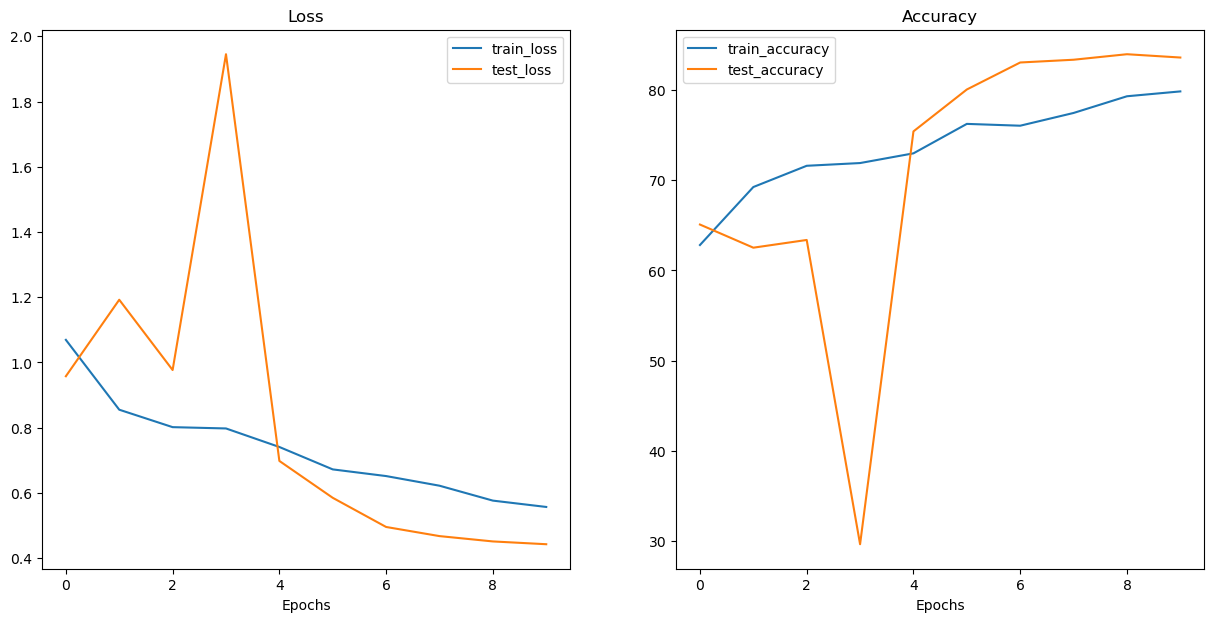

In [ ]:
set_seeds()
simple_model_V5_dropout_batchnorm_avgpool = SimpleModel_V8_dropout_batchnorm_avgpool(input_channels=3, output_size=len(class_names), dropout=0.3).to(device)

# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(params=simple_model_V5_dropout_batchnorm_avgpool.parameters(),
                             lr=0.001,
                             weight_decay=1e-4)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V5_dropout_batchnorm_avgpool,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=10,
                max_lr=3e-3)

plot_loss_curves(results)

Let's keep training it for 5 more epochs

  0%|          | 0/6 [00:00<?, ?it/s]

Epoch 0 | Train Loss: 0.5604 | Train Acc 79.39% || Test Loss: 0.4630293952157864 | Test Acc 84.37% | LR 0.001840
Epoch 1 | Train Loss: 0.6682 | Train Acc 75.79% || Test Loss: 0.5860037714816057 | Test Acc 79.06% | LR 0.002980
Epoch 2 | Train Loss: 0.6758 | Train Acc 76.60% || Test Loss: 0.5263606186669606 | Test Acc 81.81% | LR 0.002416
Epoch 3 | Train Loss: 0.6368 | Train Acc 77.47% || Test Loss: 0.47813973317925745 | Test Acc 83.15% | LR 0.001364
Epoch 4 | Train Loss: 0.5783 | Train Acc 79.56% || Test Loss: 0.4441683699305241 | Test Acc 84.74% | LR 0.000384
Epoch 5 | Train Loss: 0.5536 | Train Acc 80.30% || Test Loss: 0.42222065879748416 | Test Acc 84.92% | LR 0.000000


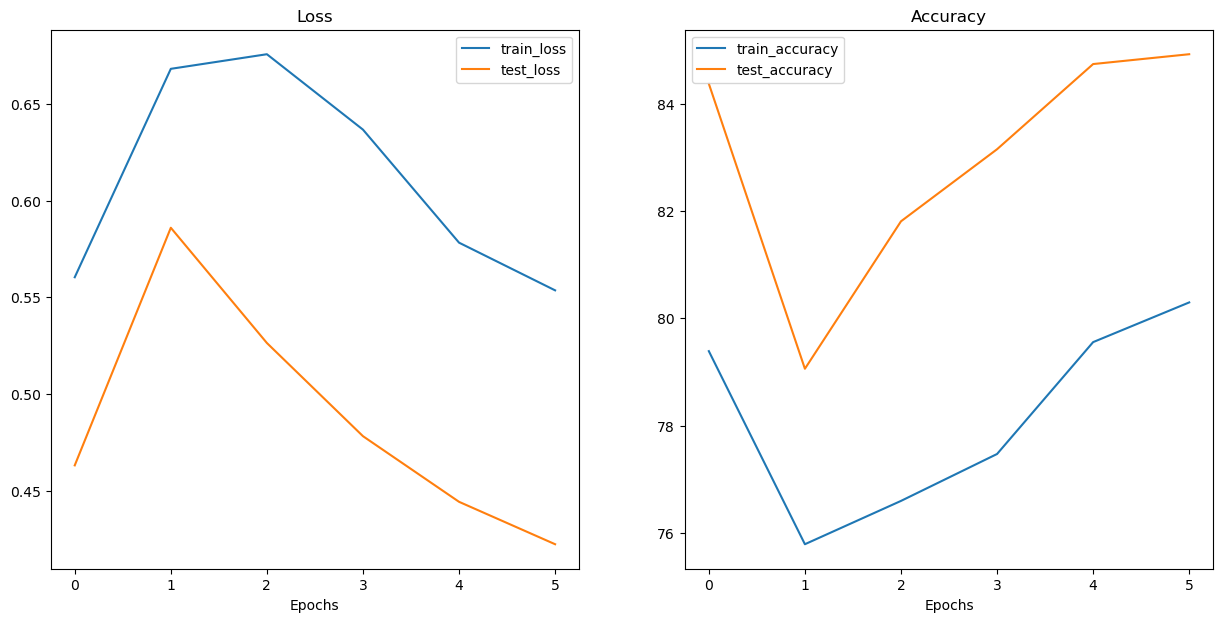

In [ ]:
# Let's keep training the model V3
results = train(model=simple_model_V5_dropout_batchnorm_avgpool,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=6,
                max_lr=3e-3)

plot_loss_curves(results)

# Let's retrained the model but now with SiLU() activation

SiLU() is slower than ReLU(). However, it can deliver better convergence than ReLU(). Let's try it out.

In [1]:
# Let's create a new model, but this time with dropout in the classifier head
from torch import nn
# Let's start by a simple model
class SimpleModel_V8_dropout_batchnorm_avgpool_SiLU(nn.Module):
    def __init__(self, input_channels: int, output_size: int, dropout: float):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(32),
            nn.SiLU(),
            nn.Conv2d(in_channels=32,
                      out_channels=32,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(32),
            nn.SiLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=32,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(64),
            nn.SiLU(),
            nn.Conv2d(in_channels=64,
                      out_channels=64,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(64),
            nn.SiLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(in_channels=64,
                      out_channels=128,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(128),
            nn.SiLU(),
            nn.Conv2d(in_channels=128,
                      out_channels=128,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(128),
            nn.SiLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.block4 = nn.Sequential(
            nn.Conv2d(in_channels=128,
                      out_channels=256,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(256),
            nn.SiLU(),
            nn.Conv2d(in_channels=256,
                      out_channels=256,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.BatchNorm2d(256),
            nn.SiLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(in_features=256,
                      out_features=128,
                      bias=True),
            nn.SiLU(),
            nn.Dropout(p=dropout),
            nn.Linear(128, output_size)
        )

    def forward(self, x):
        return self.classifier(self.avgpool(self.block4(self.block3(self.block2(self.block1(x))))))

Now, let's try to increase data information by increasing data resolution from (64x64) to (224, 224)

In [ ]:
# Let's find the mean and std of our data to then normalize it
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Load data without normalization
normal_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(data_path, transform=normal_transform)
loader = DataLoader(dataset, batch_size=32, shuffle=False)

# 2. Accumulate mean and std per batch
mean =[]
std = []

for images, _ in loader:
    # Images shape: (B, C, H, W)
    batch_mean = images.mean(dim=[0, 2, 3])
    batch_std = images.std(dim=[0, 2, 3])

    mean.append(batch_mean)
    std.append(batch_std)

# 3. Final mean and std
mean = torch.stack(mean).mean(dim=0)
std = torch.stack(std).mean(dim=0)

print(f"Dataset mean: {mean}\n")
print(f"Dataset std: {std}")

In [14]:
from torchvision import transforms

# Let's create a new transformer with these values to normalize our datasets
transform_V6 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4143, 0.3963, 0.3752],
                         std=[0.3151, 0.3071, 0.3022])
])

# Create new dataloaders
train_dataloader, test_dataloader, class_names, test_data = create_dataloaders(train_dir=train_dir,
                                                                    test_dir=test_dir,
                                                                    transform=transform_V6,
                                                                    batch_size=32)

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x1f68f5f7f40>,
 ['azurite', 'copper', 'malachite', 'pyrite', 'quartz'])

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 0 | Train Loss: 1.0669 | Train Acc 64.06% || Test Loss: 0.7633 | Test Acc 72.04% | LR 0.000458
Epoch 1 | Train Loss: 0.8724 | Train Acc 69.84% || Test Loss: 0.7458 | Test Acc 71.92% | LR 0.001315
Epoch 2 | Train Loss: 0.8334 | Train Acc 70.91% || Test Loss: 0.7045 | Test Acc 76.07% | LR 0.002286
Epoch 3 | Train Loss: 0.8517 | Train Acc 69.94% || Test Loss: 0.6308 | Test Acc 76.98% | LR 0.002916
Epoch 4 | Train Loss: 0.8159 | Train Acc 70.68% || Test Loss: 0.6114 | Test Acc 79.85% | LR 0.002983
Epoch 5 | Train Loss: 0.7416 | Train Acc 74.28% || Test Loss: 0.7195 | Test Acc 77.23% | LR 0.002849
Epoch 6 | Train Loss: 0.7454 | Train Acc 74.34% || Test Loss: 0.5671 | Test Acc 80.59% | LR 0.002596
Epoch 7 | Train Loss: 0.7127 | Train Acc 74.38% || Test Loss: 0.5600 | Test Acc 79.79% | LR 0.002246
Epoch 8 | Train Loss: 0.6857 | Train Acc 75.32% || Test Loss: 0.5476 | Test Acc 80.28% | LR 0.001829
Epoch 9 | Train Loss: 0.6771 | Train Acc 76.50% || Test Loss: 0.5002 | Test Acc 82.97% | LR

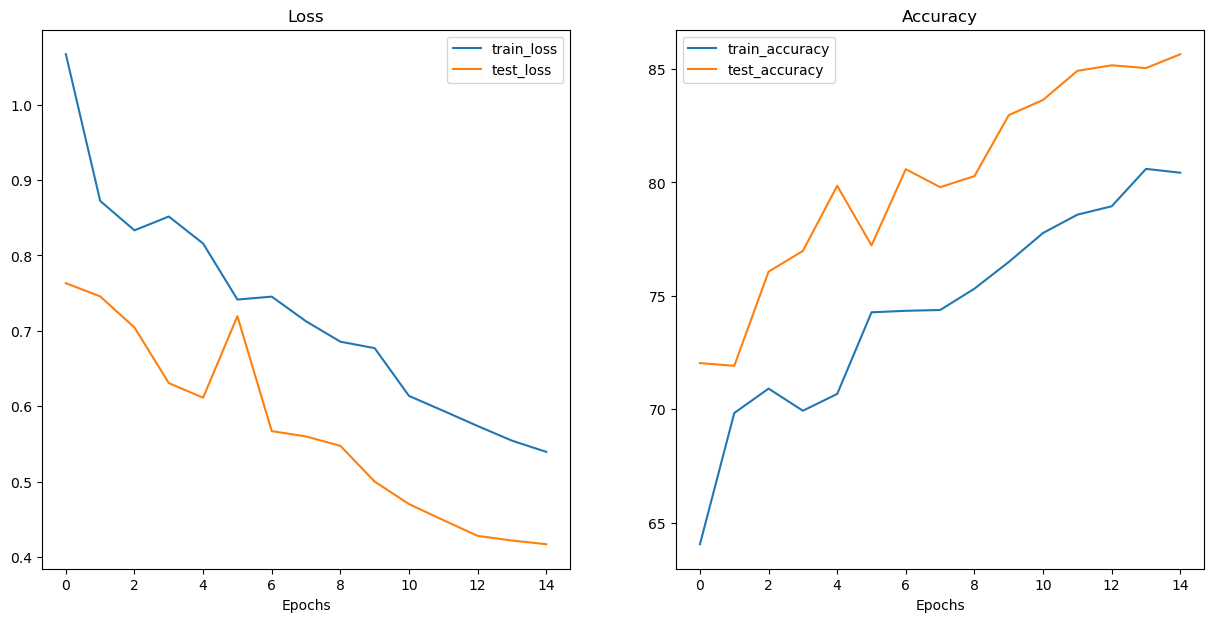

In [29]:
set_seeds()
simple_model_V6_dropout_batchnorm_avgpool_SiLU = SimpleModel_V8_dropout_batchnorm_avgpool_SiLU(input_channels=3, output_size=len(class_names), dropout=0.3).to(device)

# Setup optimizer and loss fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(params=simple_model_V6_dropout_batchnorm_avgpool_SiLU.parameters(),
                             lr=0.001,
                             weight_decay=1e-4)

# Setup accuracy function
acc_fn = Accuracy(task='multiclass', num_classes=5).to(device)
acc_fn.reset()

# Let's train the model V2
results = train(model=simple_model_V6_dropout_batchnorm_avgpool_SiLU,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                acc_fn=acc_fn,
                epochs=15,
                max_lr=3e-3)

plot_loss_curves(results)

# Let's save our so far best model

In [30]:
# Saving model
from helper_function.utils import save_model

save_model(model=simple_model_V6_dropout_batchnorm_avgpool_SiLU,
           target_dir="models",
           model_name="mineral_classifier.pth")

[INFO] Saving model to: models\mineral_classifier.pth


# Testing the model

Let's load our saved model, and make some predictions to see how well it does it.

In [15]:
# Create an instance of our architecture
mineral_classifier = SimpleModel_V8_dropout_batchnorm_avgpool_SiLU(input_channels=3, output_size=len(class_names), dropout=0.3)

# Load saved state_dict()
mineral_classifier.load_state_dict(torch.load(f="models/mineral_classifier.pth", weights_only=True))

# Send model to GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
mineral_classifier = mineral_classifier.to(device)

In [16]:
# Let's make predictions

from tqdm.auto import tqdm

y_preds = []
mineral_classifier.eval()
with torch.inference_mode():
    for X, y in tqdm(test_dataloader, desc="Making Predictions"):
        # Send data to target device
        X, y, = X.to(device), y.to(device)
        # Forward pass
        y_logits = mineral_classifier(X)
        y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)
        # Put predictions on CPU for evaluation
        y_preds.append(y_pred.cpu())
# Concatenate list of predictions into a tensor
y_preds_tensor = torch.cat(y_preds)

Making Predictions:   0%|          | 0/52 [00:00<?, ?it/s]

## Let's make a confustion matrix

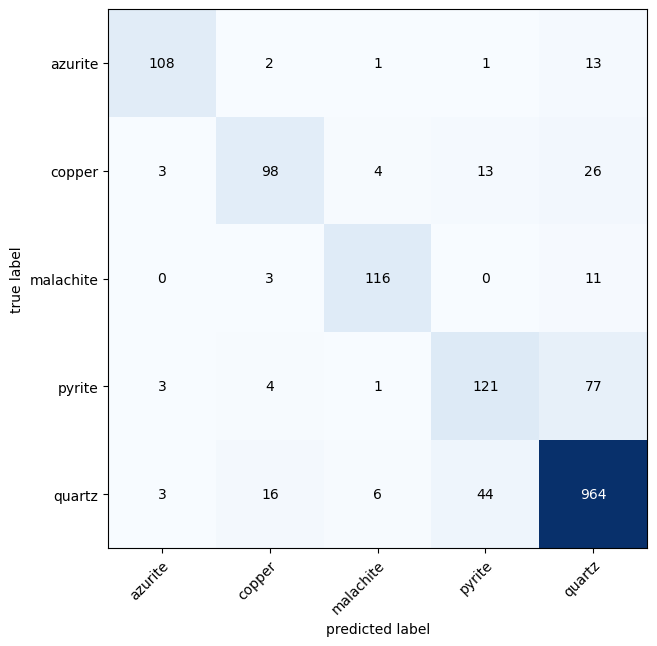

In [17]:
import mlxtend
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

# 2. Setup confusion matrix instance and compare predictions to targets
confmat = ConfusionMatrix(num_classes=len(class_names), task='multiclass')
targets_tensor = torch.tensor(test_data.targets)
confmat_tensor = confmat(preds=y_preds_tensor,
                         target=targets_tensor)

# 3. Plot the confusion matrix
fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(), # matplotlib likes working with NumPy 
    class_names=class_names, # turn the row and column labels into class names
    figsize=(10, 7)
);

In [ ]:
from typing import List

def pred_and_plot_image(
    model: torch.nn.Module,
    image_path: str,
    std: List[float],
    mean: List[float],
    class_names: List[str] = None,
    transform=None,
    device: torch.device = "cuda" if torch.cuda.is_available() else "cpu",
):
    """Makes a prediction on a target image with a trained model and plots the image.

    Args:
        model (torch.nn.Module): trained PyTorch image classification model.
        image_path (str): filepath to target image.
        class_names (List[str], optional): different class names for target image. Defaults to None.
        transform (_type_, optional): transform of target image. Defaults to None.
        device (torch.device, optional): target device to compute on. Defaults to "cuda" if torch.cuda.is_available() else "cpu".
    
    Returns:
        Matplotlib plot of target image and model prediction as title.

    Example usage:
        pred_and_plot_image(model=model,
                            image="some_image.jpeg",
                            class_names=["class_1", "class_2", "class_3"],
                            transform=torchvision.transforms.ToTensor(),
                            device=device)
    """

    # 1. Load in image and convert the tensor values to float32
    target_image = torchvision.io.read_image(str(image_path)).type(torch.float32)

    # 2. Divide the image pixel values by 255 to get them between [0, 1]
    target_image = target_image / 255.0

    # 3. Transform if necessary
    if transform:
        target_image = transform(target_image)

    # 4. Make sure the model is on the target device
    model.to(device)

    # 5. Turn on model evaluation mode and inference mode
    model.eval()
    with torch.inference_mode():
        # Add an extra dimension to the image
        target_image = target_image.unsqueeze(dim=0)

        # Make a prediction on image with an extra dimension and send it to the target device
        target_image_pred = model(target_image.to(device))

    # 6. Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # 7. Convert prediction probabilities -> prediction labels
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    # 8. De-Normalize image
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    target_image = target_image * std + mean

    # 8. Plot the image alongside the prediction and prediction probability
    plt.imshow(
        target_image.squeeze().permute(1, 2, 0)
    )  # make sure it's the right size for matplotlib
    if class_names:
        title = f"Pred: {class_names[target_image_pred_label.cpu()]} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    else:
        title = f"Pred: {target_image_pred_label} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    plt.title(title)
    plt.axis(False)


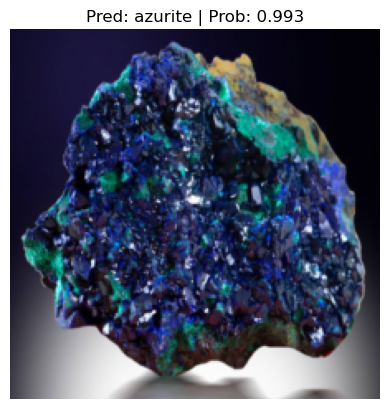

In [21]:
#from helper_function.helper_functions import pred_and_plot_image

# Setup data path
inference_data_path = Path("data/Inference_data")
# Setup a list with all images paths
inference_data_list = list(inference_data_path.glob("*"))
# Setup transform
inference_transform = torchvision.transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[0.4324, 0.4187, 0.3899],
                         std=[0.2964, 0.2916, 0.2881])
])

pred_and_plot_image(model=mineral_classifier,
                    image_path=inference_data_list[0],
                    mean=[0.4324, 0.4187, 0.3899],
                    std=[0.2964, 0.2916, 0.2881],
                    class_names=class_names,
                    transform=inference_transform,
                    device=device)

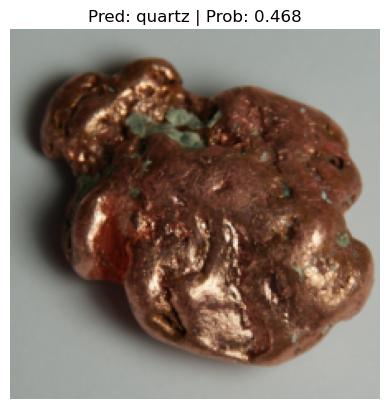

In [23]:
pred_and_plot_image(model=mineral_classifier,
                    image_path=inference_data_list[1],
                    mean=[0.4324, 0.4187, 0.3899],
                    std=[0.2964, 0.2916, 0.2881],
                    class_names=class_names,
                    transform=inference_transform,
                    device=device)

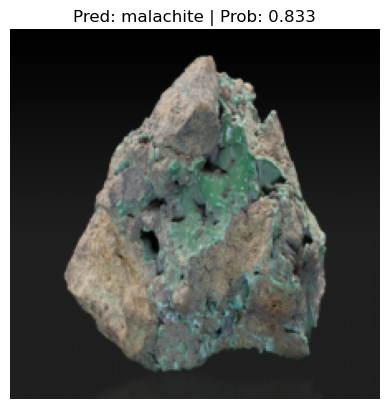

In [27]:
pred_and_plot_image(model=mineral_classifier,
                    image_path=inference_data_list[5],
                    mean=[0.4324, 0.4187, 0.3899],
                    std=[0.2964, 0.2916, 0.2881],
                    class_names=class_names,
                    transform=inference_transform,
                    device=device)

# Conclusion

We experimented with several architectures to build a model capable of recognizing mineral images from five different classes. So far, we achieved an 85% test accuracy. The model continued learning steadily, as indicated by the consistently decreasing training and validation losses, suggesting it could improve even further with more tuning.

However, we consider this performance appropriate for a model built entirely from scratch, whose main purpose is to practice the end-to-end process of model development and demonstrate the understanding behind it.

It is also important to highlight that the model was trained using only 20% of the original dataset, meaning there is still significant room for improvement if trained on the full dataset.

The final model has been saved as mineral_classifier.pth.

# MODEL DEPLOYMENT

To finish this personal project, we will create a Gradio Demo.

In [28]:
import gradio as gr

# Send Model to CPU
mineral_classifier.to("cpu")
# Check the device
next(iter(mineral_classifier.parameters())).device

device(type='cpu')

In [29]:
# Set model transform
mineral_classifier_transformer = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4324, 0.4187, 0.3899],
                         std=[0.2964, 0.2916, 0.2881])
])

In [34]:
# Replicating Gradio Workflow
from timeit import default_timer as timer
from typing import Tuple, Dict

def predict(img) -> Tuple[Dict, float]:
    """Transforms and performs a prediction on img and returns prediction and time taken.
    """
    # Start timer
    start_time = timer()

    # Transform the target image and add a batch dimension
    img = mineral_classifier_transformer(img).unsqueeze(dim=0)

    # Put model into eval() mode and turn on inference mode
    mineral_classifier.eval()
    with torch.inference_mode():
        # Pass transformed image through the model and turn the prediction logits into predictions probabilities
        pred_probs = torch.softmax(mineral_classifier(img), dim=1)

    # Create a prediction label and prediction probability dictionary for each class (this is the required format for Gradio's output parameter)
    pred_labels_and_probs = {class_names[i]: float(pred_probs[0][i]) for i in range(len(class_names))}

    # Calculate prediction time
    pred_time = round(timer() - start_time, 5)

    # Return the prediction dictionary and prediction time
    return pred_labels_and_probs, pred_time

In [35]:
# Testing pred() function
# Get a list with all test image paths
test_data_paths = list(test_dir.glob("*/*"))

# Randomly select a test image path
random_image_path = random.sample(test_data_paths, k=1)[0]

# Open the target image
image = Image.open(random_image_path)
print(f"[INFO] Predecting on image at path: {random_image_path}\n")

# Predict on the target image and print out the outputs
pred_dict, pred_time = predict(image)
print(f"Prediction label and probability dictionary: \n{pred_dict}")
print(f"Prediction time: {pred_time} seconds")

[INFO] Predecting on image at path: data\data_20_percent\test\quartz\image_0070554.jpeg

Prediction label and probability dictionary: 
{'azurite': 0.005763022229075432, 'copper': 0.1250637173652649, 'malachite': 0.0009477381245233119, 'pyrite': 0.06096266955137253, 'quartz': 0.8072628378868103}
Prediction time: 0.05422 seconds


In [39]:
# Create a list of example inputs to our Gradio Demo
example_list = [[str(filepath)] for filepath in random.sample(test_data_paths, k=6)]
example_list

[['data\\data_20_percent\\test\\quartz\\image_0053825.jpeg'],
 ['data\\data_20_percent\\test\\azurite\\image_0075851.jpeg'],
 ['data\\data_20_percent\\test\\pyrite\\image_0048305.jpeg'],
 ['data\\data_20_percent\\test\\malachite\\image_0079595.jpeg'],
 ['data\\data_20_percent\\test\\copper\\image_0053404.jpeg'],
 ['data\\data_20_percent\\test\\malachite\\image_0071209.jpeg']]

In [37]:
class_names

['azurite', 'copper', 'malachite', 'pyrite', 'quartz']

# Building a Gradio Interface

In [40]:
# Create a title, description and article strings
title = "Mineral Classifier"
description = "A CNN model built from scratch to classify images of 5 mineral types: azurite, copper, malachite, pyrite, quartz"
article = "Created for professional portafolio"

# Create the Gradio demo
demo = gr.Interface(fn=predict, # mapping function from input to output
                    inputs=gr.Image(type="pil"), # What are the inputs?
                    outputs=[gr.Label(num_top_classes=5, label="Predictions"), # What are the outputs?
                             gr.Number(label="Prediction time (s)")], # our fn has two outputs, therefore we have two outputs
                    examples=example_list,
                    title=title,
                    description=description,
                    article=article)

# Launch the demo!
demo.launch(debug=False, # print error locally?
            share=True) # generate a publically shareable URL?

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://998cfd0a7e34bb3e2c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [1]:
# Creating a 'demos' folder to store our Mineral files
import shutil
from pathlib import Path

# Create Mineral Classifier demo path
mineral_classifier_demo_path = Path("demos/mineral_classifier/")

# Remove files that might already exist there and create a new directory
if mineral_classifier_demo_path.exists():
    shutil.rmtree(mineral_classifier_demo_path)
# If it doesn't exist, then create it
mineral_classifier_demo_path.mkdir(parents=True,
                                   exist_ok=True)


In [6]:
# Creating a folder of image examples
import random
# 1. Create an example directory
mineral_classifier_examples_path = mineral_classifier_demo_path / "examples"
mineral_classifier_examples_path.mkdir(parents=True,
                                       exist_ok=True)

# 2. Collect 6 random test dataset image pahts
test_data_paths = list(test_dir.glob("*/*"))
mineral_classifier_examples = random.sample(test_data_paths, k=6)

# 3. Copy the three random images to the examples directory
for example in mineral_classifier_examples:
    destination = mineral_classifier_examples_path / example.name
    print(f"[INFO] Copying {example} to {destination}")
    shutil.copy2(src=example, dst=destination)

[INFO] Copying data\data_20_percent\test\quartz\image_0079427.jpeg to demos\mineral_classifier\examples\image_0079427.jpeg
[INFO] Copying data\data_20_percent\test\pyrite\image_0059214.jpeg to demos\mineral_classifier\examples\image_0059214.jpeg
[INFO] Copying data\data_20_percent\test\quartz\image_0079707.jpeg to demos\mineral_classifier\examples\image_0079707.jpeg
[INFO] Copying data\data_20_percent\test\quartz\image_0059540.jpeg to demos\mineral_classifier\examples\image_0059540.jpeg
[INFO] Copying data\data_20_percent\test\pyrite\image_0074970.jpeg to demos\mineral_classifier\examples\image_0074970.jpeg
[INFO] Copying data\data_20_percent\test\quartz\image_0060888.jpeg to demos\mineral_classifier\examples\image_0060888.jpeg


In [7]:
import os

# Get example filepaths in a list of lists
example_list = [["examples/" + example] for example in os.listdir(mineral_classifier_examples_path)]
example_list

[['examples/image_0059214.jpeg'],
 ['examples/image_0059540.jpeg'],
 ['examples/image_0060888.jpeg'],
 ['examples/image_0074970.jpeg'],
 ['examples/image_0079427.jpeg'],
 ['examples/image_0079707.jpeg']]

In [8]:
# Moving model to our Demo directory
# Create source path for our target model
model_path = "models/mineral_classifier.pth"

# Create a destination path for our target model
model_destination = mineral_classifier_demo_path / model_path.split("/")[1]

# Try to move the file
try:
    print(f"[INFO] Attempting to move {model_path} ti {model_destination}")
    # Move the model
    shutil.move(src=model_path,
                dst=model_destination)
    
    print(f"[INFO] Model move complete")

# If the model has already been moved, check if it exits
except:
    print(f"[INFO] No model found at {model_path}, perhaps its already been moved?")
    print(f"[INFO] Model exists at {model_destination}: {model_destination.exists()}")

[INFO] Attempting to move models/mineral_classifier.pth ti demos\mineral_classifier\mineral_classifier.pth
[INFO] Model move complete


Now, let's turn the process of creating an instance of our model to a function.

In [1]:
%%writefile demos/mineral_classifier/model.py
import torch
import torchvision

def create_mineral_classifier_model(num_classes: int=5,
                                    seed: int=42):
    """"Creates an instance of our created mineral classifier model and its corresponding transform
    
    Args:
        num_classes (int, opt): number of classes in the classifier head. Default to 5
        seed (int, optional): random seed value. Default to 42.
        
    Returns:
        model (torch.nn.Module): model arquitecture created from scratch.
        transforms (torchvision.transforms): image transform associeted to this model.
    """

    # Define the model arqutecture
    class mineral_classifier(nn.Module):
        def __init__(self, input_channels: int, output_size: int, dropout: float):
            super().__init__()

            self.block1 = nn.Sequential(
                nn.Conv2d(in_channels=input_channels,
                        out_channels=32,
                        kernel_size=3,
                        stride=1,
                        padding=1),
                nn.BatchNorm2d(32),
                nn.SiLU(),
                nn.Conv2d(in_channels=32,
                        out_channels=32,
                        kernel_size=3,
                        stride=1,
                        padding=1),
                nn.BatchNorm2d(32),
                nn.SiLU(),
                nn.MaxPool2d(kernel_size=2,
                            stride=2)
            )

            self.block2 = nn.Sequential(
                nn.Conv2d(in_channels=32,
                        out_channels=64,
                        kernel_size=3,
                        stride=1,
                        padding=1),
                nn.BatchNorm2d(64),
                nn.SiLU(),
                nn.Conv2d(in_channels=64,
                        out_channels=64,
                        kernel_size=3,
                        stride=1,
                        padding=1),
                nn.BatchNorm2d(64),
                nn.SiLU(),
                nn.MaxPool2d(kernel_size=2,
                            stride=2)
            )

            self.block3 = nn.Sequential(
                nn.Conv2d(in_channels=64,
                        out_channels=128,
                        kernel_size=3,
                        stride=1,
                        padding=1),
                nn.BatchNorm2d(128),
                nn.SiLU(),
                nn.Conv2d(in_channels=128,
                        out_channels=128,
                        kernel_size=3,
                        stride=1,
                        padding=1),
                nn.BatchNorm2d(128),
                nn.SiLU(),
                nn.MaxPool2d(kernel_size=2,
                            stride=2)
            )

            self.block4 = nn.Sequential(
                nn.Conv2d(in_channels=128,
                        out_channels=256,
                        kernel_size=3,
                        stride=1,
                        padding=1),
                nn.BatchNorm2d(256),
                nn.SiLU(),
                nn.Conv2d(in_channels=256,
                        out_channels=256,
                        kernel_size=3,
                        stride=1,
                        padding=1),
                nn.BatchNorm2d(256),
                nn.SiLU(),
                nn.MaxPool2d(kernel_size=2,
                            stride=2)
            )

            self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
            
            self.classifier = nn.Sequential(
                nn.Flatten(),
                nn.Dropout(p=dropout),
                nn.Linear(in_features=256,
                        out_features=128,
                        bias=True),
                nn.SiLU(),
                nn.Dropout(p=dropout),
                nn.Linear(128, output_size)
            )

        def forward(self, x):
            return self.classifier(self.avgpool(self.block4(self.block3(self.block2(self.block1(x))))))
        

    # Create an instance of the model
    torch.manual_seed(seed)
    model = mineral_classifier(input_channels=3,
                               output_size=num_classes,
                               dropout=0.3)
    
    # Setup tranforms
    transforms = torchvision.transforms.Compose([
    torchvision.transforms.Resize((224, 224)),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean=[0.4324, 0.4187, 0.3899],
                         std=[0.2964, 0.2916, 0.2881])
])
    
    return model, transforms

Writing demos/mineral_classifier/model.py


Turning our model Gradio app into a Python script (app.py)

In [3]:
%%writefile demos/mineral_classifier/app.py
### 1. Imports and class names setup ###
import gradio as gr
import os
import torch

from model import create_mineral_classifier_model
from timeit import default_timer as timer
from typing import Tuple, Dict

# Setup class names
class_names = ['azurite', 'copper', 'malachite', 'pyrite', 'quartz']

### 2. Model and transforms preparation ###

# Create Mineral Classifier model
mineral_classifier, mineral_classifier_transforms = create_mineral_classifier_model(
    num_classes = 5
)

# Load saved weights
mineral_classifier.load_state_dict(
    torch.load(
        f="mineral_classifier.pth",
        map_location=torch.device("cpu"),
        weights_only=True
    )
)

### 3. Predict function ###

# Create predict function
def predict(img) -> Tuple[Dict, float]:
    """Transform and performs a prediction on img and return prediction and time taken
    """
    # Start the timer
    start_time = timer()

    # Transform the target image and add a batch dimension
    img = mineral_classifier_transforms(img).unsqueeze(dim=0)

    # Put model into evaluation mode and turn on inference mode
    mineral_classifier.eval()
    with torch.inference_mode():
        # Pass the transformed image through the model and turn de prediction logits into prediction probabilitites
        pred_probs = torch.softmax(mineral_classifier(img), dim=1)

    # Create a prediction label and prediction probability dictionary for each prediction class
    pred_labels_and_probs = {class_names[i]: float(pred_probs[0][i]) for i in range(len(class_names))}

    # Calculate the prediction time
    pred_time = round(timer()- start_time, 5)

    # Return the prediction dictionary and prediction time
    return pred_labels_and_probs, pred_time

### 4. Gradio app ###

# Create a title, description and article strings
title = "Mineral Classifier"
description = "A CNN model built from scratch to classify images of 5 mineral types: azurite, copper, malachite, pyrite, quartz"
article = "Created for professional portafolio"

# Create example list from "examples/" directory
example_list = [["examples/" + example] for example in os.listdir("examples")]

# Create the Gradio demo
demo = gr.Interface(fn=predict, # mapping function from input to output
                    inputs=gr.Image(type="pil"), # What are the inputs?
                    outputs=[gr.Label(num_top_classes=5, label="Predictions"), # What are the outputs?
                             gr.Number(label="Prediction time (s)")], # our fn has two outputs, therefore we have two outputs
                    examples=example_list,
                    title=title,
                    description=description,
                    article=article)

# Launch the demo!
demo.launch()

Writing demos/mineral_classifier/app.py


Create requirements for our mineral_classifier model

In [4]:
%%writefile demos/mineral_classifier/requirements.txt
torch==1.12.0
torchvision==0.13.0
gradio==3.1.4

Writing demos/mineral_classifier/requirements.txt


In [7]:
import os
print(os.listdir("demos/mineral_classifier"))

['app.py', 'examples', 'mineral_classifier.pth', 'model.py', 'requirements.txt']
